# Deteksi Indikasi Pemalsuan Tanda Tangan dengan Siamese CNN

**Versi tanpa Google Drive.** Kedua dataset diunduh otomatis dari Kaggle.

**Cara pakai**
1. Menu **Runtime → Change runtime type → T4 GPU → Save**
2. Menu **Runtime → Run all** (izinkan kalau ada pertanyaan izin)
3. Tunggu sampai sel paling akhir. File hasil terunduh otomatis ke laptop kamu.

Hanya bagian **Pengaturan** yang boleh diubah. Kalau ada error merah, salin seluruh pesannya ke Claude.

**Isi eksperimen (bahan untuk laporan/jurnal)**
- Perbandingan 3 cara pengolahan citra (raw, gray, binary)
- Uji lintas dataset: latih di dataset 1, uji di dataset 2 yang belum pernah dilihat
- Latih gabungan dua dataset
- Uji tahan foto HP (bayangan, buram, miring, redup, noise)
- Banyak pembanding (1, 2, 3, 5 tanda tangan asli)
- Uji goyang: skor keyakinan dari kestabilan keputusan
- Ciri forensik klasik (OpenCV) digabung dengan model

## 1. Pengaturan

In [1]:
import os
# ===================== PENGATURAN =====================
DATASET_1 = "ishanikathuria/handwritten-signature-datasets"   # CEDAR: 55 orang x (24 asli + 24 palsu), hasil scan bersih
DATASET_2 = "tienen/handwritten-signature-verification"        # tanda tangan asli & palsu dari foto/scan nyata
FOLDER_1  = None    # biarkan None supaya diunduh otomatis. (Kalau sudah punya foldernya: isi path-nya)
FOLDER_2  = None

OUT_DIR   = "/kaggle/working/ttd_siamese_output" if os.path.exists("/kaggle/working") else "/content/ttd_siamese_output"   # otomatis Kaggle / Colab

SEED          = 42
EPOCHS        = 8         # batas maksimal; training berhenti sendiri kalau sudah tidak membaik
BATCH_SIZE    = 64        # lebih besar = lebih cepat. Kalau muncul error "out of memory" (OOM), turunkan jadi 32
LEARNING_RATE = 3e-4
MARGIN        = 1.0
PAIRS_PER_WRITER = 120    # jumlah pasangan "mirip" per orang di data latih

# Cara pengolahan citra yang dibandingkan. Mau cepat? Isi satu saja, contoh: ["binary"]
MODES_TO_TRY  = ["raw", "binary"]

FORCE_MODE    = "binary" # paksa cara pengolahan citra untuk model akhir. Isi None supaya dipilih otomatis dari validasi
MAX_WRITERS_D2 = 120     # batasi jumlah orang dari dataset 2 (None = semua). Isi 120 kalau mau lebih cepat.
N_SHAKE       = 6         # jumlah versi "goyang" untuk uji keyakinan
ABSTAIN_FRAC  = 0.20      # bagian hasil yang paling tidak yakin dilabeli "ragu"

QUICK_TEST    = False     # True = tes cepat (data kecil, 2 epoch) hanya untuk memastikan semua sel jalan
ALLOW_CPU     = False     # biarkan False. GPU wajib supaya training tidak berjam-jam.
# ======================================================
if QUICK_TEST:
    EPOCHS, PAIRS_PER_WRITER, N_SHAKE = 2, 30, 4

## 2. Cek GPU

In [2]:
import os, sys, json, random, shutil, hashlib, itertools, re, time, warnings, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
warnings.filterwarnings("ignore")

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__, "| GPU:", gpus)
assert gpus or ALLOW_CPU or QUICK_TEST, (
    "GPU belum aktif! Buka Runtime -> Change runtime type -> T4 GPU -> Save, "
    "lalu jalankan lagi dari atas (Runtime -> Run all)."
)

os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

TensorFlow: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3. Pengolahan citra dan alat bantu

Tiga file kecil ditulis ke folder kerja. **File yang sama persis** nanti dipakai juga oleh aplikasi demo, jadi tanda tangan yang diperiksa di demo diolah dengan cara yang sama seperti saat training.

- `preprocess.py`: pengolahan citra (ratakan cahaya, pisahkan tinta dengan Otsu, buang bintik, potong area tanda tangan, ukuran seragam)
- `forensik.py`: ciri klasik (kemiringan, ketebalan goresan, dll) dan penjelasan "kenapa"
- `gangguan.py`: gangguan buatan (meniru foto HP) dan "uji goyang"

In [3]:
%pip install -q kagglehub scikit-image

Note: you may need to restart the kernel to use updated packages.


In [4]:
%%writefile preprocess.py
"""
preprocess.py - pengolahan citra tanda tangan.

File ini dipakai di DUA tempat supaya hasilnya selalu sama:
  1. notebook training (Google Colab)
  2. aplikasi demo (folder demo/)

Aturan keluaran: gambar ukuran (out_h, out_w), nilai 0..1,
  - latar belakang = 0 (hitam)
  - goresan tanda tangan = mendekati 1 (terang)
"""

import cv2
import numpy as np
from PIL import Image

IMG_H = 128
IMG_W = 256

# raw    : hanya grayscale + resize (cara awal, dipakai sebagai pembanding)
# gray   : koreksi cahaya + buang bintik + crop + resize, tinta tetap abu-abu
# binary : sama seperti gray, tetapi tinta dijadikan hitam-putih murni (Otsu)
MODES = ("raw", "gray", "binary")


def load_gray(source):
    """Baca gambar dari path / file-like object menjadi array uint8 2D (0=hitam, 255=putih)."""
    img = Image.open(source)
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        latar = Image.new("RGBA", img.size, (255, 255, 255, 255))
        latar.alpha_composite(img)
        img = latar
    return np.array(img.convert("L"), dtype=np.uint8)


def _fit_to_canvas(img, out_h, out_w):
    """Perkecil/perbesar tanpa merusak rasio, lalu taruh di tengah kanvas hitam."""
    h, w = img.shape
    skala = min(out_h / h, out_w / w)
    new_w = max(1, int(round(w * skala)))
    new_h = max(1, int(round(h * skala)))
    kecil = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    kanvas = np.zeros((out_h, out_w), dtype=np.uint8)
    y0 = (out_h - new_h) // 2
    x0 = (out_w - new_w) // 2
    kanvas[y0:y0 + new_h, x0:x0 + new_w] = kecil
    return kanvas


def _limit_size(gray, max_side=1600):
    """Foto kamera bisa sangat besar; kecilkan dulu supaya proses cepat."""
    h, w = gray.shape
    if max(h, w) <= max_side:
        return gray
    s = max_side / max(h, w)
    return cv2.resize(gray, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)


def _flatten_lighting(gray):
    """Ratakan cahaya (bayangan / kertas tidak rata) dengan membagi gambar dengan latarnya."""
    h, w = gray.shape
    f = max(1, max(h, w) // 400)          # hitung latar pada gambar kecil supaya cepat
    kecil = cv2.resize(gray, (max(1, w // f), max(1, h // f)), interpolation=cv2.INTER_AREA)
    sigma = max(kecil.shape) / 20.0
    latar = cv2.GaussianBlur(kecil, (0, 0), sigmaX=sigma)
    latar = cv2.resize(latar, (w, h), interpolation=cv2.INTER_LINEAR)
    latar = np.maximum(latar, 1)
    return cv2.divide(gray, latar, scale=255)


def _remove_specks(mask, min_area=10):
    """Buang bintik kecil (debu hasil scan). Versi cepat tanpa perulangan per bintik."""
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    simpan = stats[:, cv2.CC_STAT_AREA] >= min_area
    simpan[0] = False                      # label 0 = latar
    return (simpan[labels].astype(np.uint8)) * 255


def _core(gray):
    """Langkah bersama untuk mode gray dan binary: ratakan cahaya, pisahkan tinta (Otsu), buang bintik."""
    gray = _limit_size(np.asarray(gray, dtype=np.uint8))
    rata = _flatten_lighting(gray)
    halus = cv2.GaussianBlur(rata, (3, 3), 0)
    _, mask = cv2.threshold(halus, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    mask = _remove_specks(mask)
    return rata, mask


def _crop(tinta, mask):
    ys, xs = np.where(mask > 0)
    h, w = tinta.shape
    margin = max(2, int(0.03 * max(h, w)))
    y1, y2 = max(0, ys.min() - margin), min(h, ys.max() + margin + 1)
    x1, x2 = max(0, xs.min() - margin), min(w, xs.max() + margin + 1)
    return tinta[y1:y2, x1:x2]


def _raw(gray, out_h, out_w):
    terbalik = 255 - np.asarray(gray, dtype=np.uint8)
    hasil = cv2.resize(terbalik, (out_w, out_h), interpolation=cv2.INTER_AREA)
    return hasil.astype(np.float32) / 255.0


def preprocess_signature(gray, mode="binary", out_h=IMG_H, out_w=IMG_W, return_steps=False):
    """
    gray : array uint8 2D (0=hitam ... 255=putih)
    return: array float32 (out_h, out_w) 0..1  (atau (hasil, dict langkah) bila return_steps=True)
    """
    if mode not in MODES:
        raise ValueError(f"mode harus salah satu dari {MODES}")

    gray = np.asarray(gray, dtype=np.uint8)
    steps = {"asli": gray}

    if mode == "raw":
        hasil = _raw(gray, out_h, out_w)
        steps["hasil"] = hasil
        return (hasil, steps) if return_steps else hasil

    rata, mask = _core(gray)
    steps["cahaya_rata"] = rata
    steps["mask"] = mask

    if not mask.any():
        hasil = np.zeros((out_h, out_w), dtype=np.float32)
        steps["hasil"] = hasil
        return (hasil, steps) if return_steps else hasil

    tinta = mask if mode == "binary" else np.where(mask > 0, 255 - rata, 0).astype(np.uint8)
    potong = _crop(tinta, mask)
    steps["potong"] = potong
    if mode == "gray":                      # untuk ciri forensik selalu sediakan potongan hitam-putih
        steps["potong_biner"] = _crop(mask, mask)
    hasil = _fit_to_canvas(potong, out_h, out_w).astype(np.float32) / 255.0
    steps["hasil"] = hasil
    return (hasil, steps) if return_steps else hasil


def preprocess_all(gray, modes=MODES, out_h=IMG_H, out_w=IMG_W):
    """
    Olah satu gambar untuk beberapa mode sekaligus (lebih cepat dari memanggil satu-satu).
    return: (dict mode -> array float32, potongan_biner uint8 atau None)
    potongan_biner dipakai untuk menghitung ciri forensik.
    """
    gray = np.asarray(gray, dtype=np.uint8)
    hasil, potong_biner = {}, None
    if "raw" in modes:
        hasil["raw"] = _raw(gray, out_h, out_w)
    perlu_inti = any(m in modes for m in ("gray", "binary"))
    if perlu_inti:
        rata, mask = _core(gray)
        if not mask.any():
            for m in ("gray", "binary"):
                if m in modes:
                    hasil[m] = np.zeros((out_h, out_w), dtype=np.float32)
        else:
            potong_biner = _crop(mask, mask)
            if "binary" in modes:
                hasil["binary"] = _fit_to_canvas(potong_biner, out_h, out_w).astype(np.float32) / 255.0
            if "gray" in modes:
                tinta = np.where(mask > 0, 255 - rata, 0).astype(np.uint8)
                hasil["gray"] = _fit_to_canvas(_crop(tinta, mask), out_h, out_w).astype(np.float32) / 255.0
    return hasil, potong_biner

Writing preprocess.py


In [5]:
%%writefile forensik.py
"""
forensik.py - ciri tanda tangan yang dihitung dengan pengolahan citra klasik (tanpa deep learning).

Ciri ini dipakai untuk dua hal:
  1. Laporan forensik mini: menjelaskan KENAPA dua tanda tangan dianggap mirip / beda.
  2. Digabung dengan jarak dari model Siamese (fusi), lalu diuji apakah error turun.
"""

import cv2
import numpy as np

try:
    from skimage.morphology import skeletonize as _skeletonize
except Exception:  # noqa: BLE001
    _skeletonize = None

NAMA_CIRI = [
    "rasio_lebar_tinggi",
    "kepadatan_tinta",
    "kemiringan",
    "ketebalan_goresan",
    "jumlah_bagian",
    "panjang_goresan",
    "posisi_x",
    "posisi_y",
]

LABEL_CIRI = {
    "rasio_lebar_tinggi": "Bentuk (lebar dibanding tinggi)",
    "kepadatan_tinta": "Kepadatan tinta",
    "kemiringan": "Kemiringan umum",
    "ketebalan_goresan": "Ketebalan goresan",
    "jumlah_bagian": "Jumlah bagian terpisah (angkat pena)",
    "panjang_goresan": "Panjang total goresan",
    "posisi_x": "Letak pusat tinta (kiri-kanan)",
    "posisi_y": "Letak pusat tinta (atas-bawah)",
}

# ciri yang dibandingkan dengan rasio (log) vs selisih biasa
_LOG = {"rasio_lebar_tinggi", "kepadatan_tinta", "ketebalan_goresan", "jumlah_bagian", "panjang_goresan"}


def extract_features(potong):
    """potong: array uint8 hasil crop mask tinta (0/255). return: vektor float32 panjang 8, atau None."""
    if potong is None or potong.size == 0 or not potong.any():
        return None
    h0, w0 = potong.shape
    s = 96.0 / h0
    m = cv2.resize(potong, (max(8, int(round(w0 * s))), 96), interpolation=cv2.INTER_AREA) > 64
    ys, xs = np.nonzero(m)
    if len(ys) < 5:
        return None
    luas = float(m.sum())
    rasio = w0 / h0
    kepadatan = luas / m.size

    mu20, mu02 = float(np.var(xs)), float(np.var(ys))
    mu11 = float(np.mean((xs - xs.mean()) * (ys - ys.mean())))
    miring = float(np.degrees(0.5 * np.arctan2(2 * mu11, mu20 - mu02 + 1e-9)))

    if _skeletonize is not None:
        rangka = _skeletonize(m)
        panjang = float(rangka.sum())
    else:
        panjang = luas / 3.0
    tebal = luas / max(panjang, 1.0)
    n_bagian = float(cv2.connectedComponents(m.astype(np.uint8), connectivity=8)[0] - 1)
    panjang_norm = panjang / float(np.hypot(*m.shape))
    cx, cy = float(xs.mean() / m.shape[1]), float(ys.mean() / m.shape[0])
    return np.array([rasio, kepadatan, miring, tebal, n_bagian, panjang_norm, cx, cy], dtype=np.float32)


def feature_diffs(v1, v2):
    """Selisih per ciri antara dua tanda tangan (selalu >= 0). Dipakai untuk fusi dan untuk laporan."""
    out = np.zeros(len(NAMA_CIRI), dtype=np.float32)
    for i, nama in enumerate(NAMA_CIRI):
        a, b = float(v1[i]), float(v2[i])
        if nama in _LOG:
            out[i] = abs(np.log((a + 1e-3) / (b + 1e-3)))
        elif nama == "kemiringan":
            d = abs(a - b)
            out[i] = min(d, 180.0 - d)
        else:
            out[i] = abs(a - b)
    return out


def _fmt(nama, v):
    if nama == "kemiringan":
        return f"{v:.0f} derajat"
    if nama == "jumlah_bagian":
        return f"{v:.0f} bagian"
    if nama in ("posisi_x", "posisi_y"):
        return f"{v * 100:.0f}%"
    if nama == "kepadatan_tinta":
        return f"{v * 100:.1f}%"
    return f"{v:.2f}"


def explain(v_ref, v_qry, batas):
    """
    Laporan forensik mini.
    batas: dict nama_ciri -> [p75, p95] dari selisih pada pasangan tanda tangan ASLI (dihitung di notebook).
    return: list dict {ciri, label, pembanding, diperiksa, tingkat, kalimat}
    """
    d = feature_diffs(v_ref, v_qry)
    hasil = []
    for i, nama in enumerate(NAMA_CIRI):
        p75, p95 = batas[nama]
        if d[i] <= p75:
            tingkat = "mirip"
        elif d[i] <= p95:
            tingkat = "agak beda"
        else:
            tingkat = "beda"
        a, b = _fmt(nama, v_ref[i]), _fmt(nama, v_qry[i])
        hasil.append({
            "ciri": nama,
            "label": LABEL_CIRI[nama],
            "pembanding": a,
            "diperiksa": b,
            "tingkat": tingkat,
            "kalimat": f"{LABEL_CIRI[nama]}: pembanding {a}, diperiksa {b} ({tingkat}).",
            "selisih": float(d[i]),
        })
    return hasil

Writing forensik.py


In [6]:
%%writefile gangguan.py
"""
gangguan.py - gangguan buatan pada gambar tanda tangan.

Dua kegunaan:
  1. Meniru kondisi foto dari HP (bayangan, buram, miring, redup, noise, kompresi JPEG)
     untuk menguji ketahanan model.
  2. "Uji goyang": membuat beberapa versi sedikit bergeser/berputar dari satu gambar
     untuk mengukur seberapa stabil keputusan model.
"""

import cv2
import numpy as np


def bayangan(gray, rng):
    h, w = gray.shape
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    sudut = rng.uniform(0, 2 * np.pi)
    proj = (xx / w - 0.5) * np.cos(sudut) + (yy / h - 0.5) * np.sin(sudut)
    sig = 1.0 / (1.0 + np.exp(-proj * rng.uniform(4, 9)))
    kuat = rng.uniform(0.35, 0.6)
    faktor = 1.0 - kuat * sig
    return np.clip(gray.astype(np.float32) * faktor, 0, 255).astype(np.uint8)


def buram(gray, rng):
    sigma = rng.uniform(1.0, 2.2) * max(gray.shape) / 300.0
    return cv2.GaussianBlur(gray, (0, 0), sigmaX=max(sigma, 0.8))


def miring(gray, rng):
    h, w = gray.shape
    sudut = rng.uniform(4, 9) * rng.choice([-1, 1])
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=255)


def redup(gray, rng):
    alpha = rng.uniform(0.45, 0.65)     # kontras turun
    beta = rng.uniform(0, 25)
    return np.clip(gray.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)


def derau(gray, rng):
    n = rng.normal(0, rng.uniform(10, 20), gray.shape)
    return np.clip(gray.astype(np.float32) + n, 0, 255).astype(np.uint8)


def kompresi(gray, rng):
    ok, buf = cv2.imencode(".jpg", gray, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(15, 35))])
    return cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)


def foto_hp(gray, rng):
    """Gabungan: agak miring + bayangan + sedikit buram + noise + kompresi (mirip foto kertas dari HP)."""
    g = miring(gray, rng)
    g = bayangan(g, rng)
    g = cv2.GaussianBlur(g, (0, 0), sigmaX=max(0.8, 0.7 * max(g.shape) / 300.0))
    g = derau(g, rng)
    return kompresi(g, rng)


KONDISI = {
    "bayangan": bayangan,
    "buram": buram,
    "miring": miring,
    "redup": redup,
    "noise": derau,
    "foto_hp": foto_hp,
}


def shake_variants(arr, n=10, seed=0, max_shift=0.04, max_rot=3.0, max_scale=0.05):
    """
    arr: array float32 (H, W) hasil pengolahan citra (0..1, latar 0).
    return: array (n, H, W, 1). Setiap versi digeser, diputar, dan diperbesar/diperkecil sedikit.
    """
    rng = np.random.default_rng(seed)
    h, w = arr.shape
    out = np.empty((n, h, w, 1), dtype=np.float32)
    for i in range(n):
        sudut = rng.uniform(-max_rot, max_rot)
        skala = 1.0 + rng.uniform(-max_scale, max_scale)
        M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, skala)
        M[0, 2] += rng.uniform(-max_shift, max_shift) * w
        M[1, 2] += rng.uniform(-max_shift, max_shift) * h
        out[i, :, :, 0] = cv2.warpAffine(arr, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
    return out

Writing gangguan.py


In [7]:
sys.path.insert(0, os.getcwd())
import importlib, preprocess, forensik, gangguan
for _m in (preprocess, forensik, gangguan):
    importlib.reload(_m)
from preprocess import preprocess_signature, preprocess_all, load_gray, IMG_H, IMG_W, MODES
from forensik import extract_features, feature_diffs, explain, NAMA_CIRI
from gangguan import KONDISI, shake_variants
print("Ukuran gambar untuk model:", IMG_H, "x", IMG_W)
assert all(m in MODES for m in MODES_TO_TRY), f"MODES_TO_TRY harus berisi {MODES}"

Ukuran gambar untuk model: 128 x 256


## 4. Mengunduh dan membaca kedua dataset

Dataset 1 berformat CEDAR (`original_X_Y.png` dan `forgeries_X_Y.png`). Dataset 2 berisi foto lembar tanda tangan (`real/<lembar>/<potongan>`); pemiliknya dibaca dari nama lembar. Hasil bacaan ditampilkan supaya bisa dicek.

Gambar dataset 2 yang sama persis dengan gambar dataset 1 dibuang, supaya uji lintas dataset benar-benar adil.

In [8]:
import kagglehub

EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
KATA_PALSU = ("fake", "forg", "false", "palsu", "fraud", "imitat", "skilled")
KATA_ASLI  = ("real", "genuine", "original", "orig", "authentic", "true", "asli")
KATA_ABAIKAN = {"train", "test", "val", "valid", "validation", "crop", "crops", "image", "images", "data",
                "dataset", "signature", "signatures", "full", "sign", "versions", "archive"}
POLA_CEDAR = re.compile(r"^(original|forgeries)_(\d+)_(\d+)\.(png|jpg|jpeg|bmp|tif|tiff)$", re.IGNORECASE)


def siapkan_folder(nama, manual):
    if manual:
        return manual
    print("Mengunduh:", nama, "(bisa beberapa menit untuk dataset besar)")
    return kagglehub.dataset_download(nama)


def daftar_gambar(root):
    hasil = []
    for akar, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith(EXT):
                hasil.append(os.path.relpath(os.path.join(akar, f), root))
    return sorted(hasil)


def tebak_label(rel):
    """True = asli, False = palsu, None = tidak jelas. Dilihat dari nama folder dan nama file."""
    bagian = [b.lower() for b in rel.replace("\\", "/").split("/")]
    bagian[-1] = os.path.splitext(bagian[-1])[0]
    if any(k in b for b in bagian for k in KATA_PALSU):
        return False
    if any(k in b for b in bagian for k in KATA_ASLI):
        return True
    return None


def _token_bersih(teks):
    return [t for t in re.split(r"[^A-Za-z0-9]+", teks) if t and not t.lower().startswith(KATA_ASLI + KATA_PALSU)]


def kunci_token_pertama(rel):
    t = _token_bersih(os.path.splitext(os.path.basename(rel))[0])
    return t[0] if t else None


def kunci_angka_pertama(rel):
    m = re.search(r"\d+", os.path.splitext(os.path.basename(rel))[0])
    return m.group(0) if m else None


def kunci_folder(rel):
    for b in reversed(rel.replace("\\", "/").split("/")[:-1]):
        t = _token_bersih(b)
        if t and not any(b.lower().startswith(k) for k in KATA_ABAIKAN):
            return b
    return None


def baca_dataset(root, tag, nama):
    print("\n" + "=" * 70 + f"\n{tag}: {nama}\n{root}\n" + "=" * 70)
    rels = daftar_gambar(root)
    print("Jumlah gambar ditemukan:", len(rels))
    if not rels:
        return pd.DataFrame(columns=["path", "dataset", "writer", "is_genuine"])

    # struktur folder (ringkas)
    atas = pd.Series([r.replace("\\", "/").split("/")[0] if "/" in r.replace("\\", "/") else "(langsung)" for r in rels]).value_counts()
    print("Isi folder teratas:", atas.head(8).to_dict())

    cedar = [r for r in rels if POLA_CEDAR.match(os.path.basename(r))]
    if len(cedar) >= 0.8 * len(rels):
        print("Format dikenali: CEDAR (original_X_Y / forgeries_X_Y)")
        baris = []
        for r in cedar:
            m = POLA_CEDAR.match(os.path.basename(r))
            baris.append({"path": os.path.join(root, r), "writer": f"{tag}_{int(m.group(2))}",
                          "is_genuine": m.group(1).lower() == "original"})
        df = pd.DataFrame(baris)
    else:
        print("Format dikenali: umum (label dari nama folder/file, pemilik dari nama file)")
        ada_crop = [r for r in rels if "crop" in r.lower()]
        if len(ada_crop) >= 50:
            print(f"  Folder/nama 'crop' ditemukan: hanya {len(ada_crop)} potongan tanda tangan yang dipakai "
                  f"({len(rels) - len(ada_crop)} gambar lembar penuh diabaikan)")
            rels = ada_crop
        label = {r: tebak_label(r) for r in rels}
        tanpa = [r for r in rels if label[r] is None]
        if tanpa:
            print(f"  {len(tanpa)} gambar tidak jelas asli/palsunya, dilewati. Contoh:", tanpa[:3])
        rels = [r for r in rels if label[r] is not None]

        pilihan = {}
        for nama_k, fn in (("token_pertama_nama_file", kunci_token_pertama),
                           ("angka_pertama_nama_file", kunci_angka_pertama),
                           ("nama_folder", kunci_folder)):
            k = {r: fn(r) for r in rels}
            g = pd.Series([k[r] for r in rels if label[r] and k[r] is not None]).value_counts()
            pilihan[nama_k] = (int((g >= 3).sum()), k)
        terbaik = max(pilihan, key=lambda n: pilihan[n][0])
        print("  Cara menentukan pemilik tanda tangan:", terbaik, {n: v[0] for n, v in pilihan.items()}, "(jumlah orang valid)")
        kunci = pilihan[terbaik][1]
        df = pd.DataFrame([{"path": os.path.join(root, r), "writer": f"{tag}_{kunci[r]}", "is_genuine": bool(label[r])}
                           for r in rels if kunci[r] is not None])

    df["dataset"] = tag
    print(f"Hasil: {len(df)} gambar | {df.writer.nunique()} orang | asli {int(df.is_genuine.sum())} | palsu {int((~df.is_genuine).sum())}")
    print("Contoh hasil tebakan (cek apakah masuk akal):")
    for _, r in df.sample(min(5, len(df)), random_state=0).iterrows():
        print("   ", os.path.relpath(r.path, root), "->", r.writer, "ASLI" if r.is_genuine else "PALSU")
    # ukuran gambar: kalau sangat besar, kemungkinan itu foto satu lembar penuh, bukan satu tanda tangan
    from PIL import Image
    ukuran = []
    for p in df.path.sample(min(30, len(df)), random_state=1):
        try:
            ukuran.append(Image.open(p).size)
        except Exception:
            pass
    if ukuran:
        w, h = np.median([u[0] for u in ukuran]), np.median([u[1] for u in ukuran])
        print(f"Ukuran gambar tipikal: {int(w)} x {int(h)} piksel")
        if max(w, h) > 1800:
            print("  PERINGATAN: gambar sangat besar. Mungkin ini foto satu lembar penuh, bukan satu tanda tangan. Kabari Claude.")
    return df


def baca_d2_toloka(root, tag):
    """Struktur dataset 2: <root>/.../real/<nama lembar>.jpg/<k>__<nama lembar>.jpg.jpg  (dan 'forged' yang sama).
    Pemilik tanda tangan: bagian lid_<angka> pada nama lembar (kalau ada); kalau tidak ada, tiap lembar dianggap satu orang.
    Tanda tangan palsu belum bisa dihubungkan ke pemiliknya, jadi tidak dipakai (dihitung saja untuk laporan)."""
    base = real_dir = forg_dir = None
    for akar, dirs, _ in os.walk(root):
        low = {d.lower(): d for d in dirs}
        f = next((low[k] for k in ("forged", "forge", "fake") if k in low), None)
        if "real" in low and f:
            base, real_dir, forg_dir = akar, low["real"], f
            break
    if base is None:
        return None
    print("Struktur Toloka dikenali di:", base)
    baris, n_lembar, n_lid = [], 0, 0
    for d in sorted(os.listdir(os.path.join(base, real_dir))):
        p = os.path.join(base, real_dir, d)
        if not os.path.isdir(p):
            continue
        n_lembar += 1
        m = re.match(r"lid_(\d+)_", d)
        n_lid += bool(m)
        w = f"{tag}_lid{m.group(1)}" if m else f"{tag}_lembar_{d}"
        for fn in sorted(os.listdir(p)):
            if fn.lower().endswith(EXT):
                baris.append({"path": os.path.join(p, fn), "writer": w, "is_genuine": True})
    n_forged = sum(1 for _, _, fs in os.walk(os.path.join(base, forg_dir)) for fn in fs if fn.lower().endswith(EXT))
    df = pd.DataFrame(baris)
    df["dataset"] = tag
    print(f"  lembar asli: {n_lembar} (berawalan lid_: {n_lid}) | potongan asli: {len(df)} | orang/kelompok: {df.writer.nunique()}")
    print(f"  tanda tangan palsu di folder forged: {n_forged} (tidak dipakai: belum bisa dihubungkan ke pemiliknya)")
    print("  Catatan: pasangan 'mirip' di dataset 2 berasal dari lembar/pemilik yang sama, jadi ujian D2 mengukur"
          " 'orang yang sama vs beda', dan sebagian bisa dipengaruhi kondisi foto yang sama.")
    return df


root1 = siapkan_folder(DATASET_1, FOLDER_1)
d1 = baca_dataset(root1, "D1", DATASET_1)
try:
    root2 = siapkan_folder(DATASET_2, FOLDER_2)
    d2 = baca_d2_toloka(root2, "D2")
    if d2 is None:
        print("Struktur Toloka tidak dikenali, memakai pembaca umum.")
        d2 = baca_dataset(root2, "D2", DATASET_2)
except Exception as e:
    print("\nDataset 2 gagal diunduh/dibaca:", repr(e)[:300])
    print("Notebook tetap lanjut memakai dataset 1 saja (uji lintas dataset dilewati).")
    d2 = pd.DataFrame(columns=["path", "dataset", "writer", "is_genuine"])
assert len(d1) > 0, "Dataset 1 kosong. Salin seluruh output sel ini ke Claude."

Mengunduh: ishanikathuria/handwritten-signature-datasets (bisa beberapa menit untuk dataset besar)

D1: ishanikathuria/handwritten-signature-datasets
/kaggle/input/datasets/ishanikathuria/handwritten-signature-datasets
Jumlah gambar ditemukan: 16680
Isi folder teratas: {'BHSig260-Hindi': 8640, 'BHSig260-Bengali': 5400, 'CEDAR': 2640}
Format dikenali: umum (label dari nama folder/file, pemilik dari nama file)
  14040 gambar tidak jelas asli/palsunya, dilewati. Contoh: ['BHSig260-Bengali/BHSig260-Bengali/1/B-S-1-F-01.tif', 'BHSig260-Bengali/BHSig260-Bengali/1/B-S-1-F-02.tif', 'BHSig260-Bengali/BHSig260-Bengali/1/B-S-1-F-03.tif']
  Cara menentukan pemilik tanda tangan: token_pertama_nama_file {'token_pertama_nama_file': 55, 'angka_pertama_nama_file': 55, 'nama_folder': 55} (jumlah orang valid)
Hasil: 2640 gambar | 55 orang | asli 1320 | palsu 1320
Contoh hasil tebakan (cek apakah masuk akal):
    CEDAR/CEDAR/34/original_34_5.png -> D1_34 ASLI
    CEDAR/CEDAR/35/original_35_17.png -> D1_35

### Pemeriksaan struktur dataset 2 (hanya menampilkan, tidak mengubah apa pun)
Kirim output sel ini ke Claude. Dari sini terlihat dari mana pemilik tanda tangan bisa ditentukan dengan benar.

In [9]:
try:
    for f in glob.glob(root2 + "/**/*", recursive=True):
        if f.lower().endswith((".tsv", ".csv", ".txt", ".json", ".md")):
            print("FILE:", f, os.path.getsize(f), "byte")
            print(open(f, errors="ignore").read()[:1500])
            print("-" * 50)
    for sub in ("real", "forged"):
        for d in glob.glob(root2 + f"/**/{sub}", recursive=True):
            isi = sorted(os.listdir(d))
            print(d, len(isi), isi[:6])
            if isi and os.path.isdir(os.path.join(d, isi[0])):
                print("   isi folder pertama:", sorted(os.listdir(os.path.join(d, isi[0])))[:6])
except NameError:
    print("Dataset 2 tidak terunduh, pemeriksaan dilewati.")

FILE: /kaggle/input/datasets/tienen/handwritten-signature-verification/assignments_07-02-2022.tsv 85585 byte
INPUT:id	OUTPUT:image	HINT:text	HINT:default_language	ASSIGNMENT:link	ASSIGNMENT:task_id	ASSIGNMENT:assignment_id	ACCEPT:verdict	ACCEPT:comment
https://storage.googleapis.com/hand-signatures-toloka/signatures/8__lid_1644025059148_1_JPEG_20220204_223714.jpg.jpg	ru.0187d045-7110-4bf1-904c-4f730aae0205			https://toloka.yandex.ru/task/31531273/0001e12109--61fdebbf404d017ba83b07cf	27489662-09e2-4f8f-94b7-75cfd305f24d	0001e12109--61fdebbf404d017ba83b07cf	+	
https://storage.googleapis.com/hand-signatures-toloka/signatures/8__lid_1643975554739_1_JPEG_20220204_125222.jpg.jpg	ru.b3b132ab-1839-4910-953b-1d5ef16047d8			https://toloka.yandex.ru/task/31531273/0001e12109--61fdf16af73c4b173c29b8c6	7026cd16-da12-4909-982e-fda139ffda70	0001e12109--61fdf16af73c4b173c29b8c6	+	
https://storage.googleapis.com/hand-signatures-toloka/signatures/8__lid_1644022634248_1_JPEG_20220205_075630.jpg.jpg	ru.dda

In [10]:
# Informasi tambahan (hanya mencetak): apakah palsu bisa dihubungkan ke asli lewat file TSV/CSV
try:
    R = root2 + "/data/data"
    tsv = pd.read_csv(glob.glob(root2 + "/**/assignments*.tsv", recursive=True)[0], sep="\t")
    tsv["crop"] = tsv["INPUT:id"].str.split("/").str[-1]
    ada = {sub: {f for d in os.listdir(f"{R}/{sub}") if os.path.isdir(f"{R}/{sub}/{d}") for f in os.listdir(f"{R}/{sub}/{d}")}
           for sub in ("real", "forged")}
    print("TSV:", len(tsv), "baris | OUTPUT:image unik:", tsv["OUTPUT:image"].nunique())
    print("crop TSV di folder real:", int(tsv["crop"].isin(ada["real"]).sum()), "| di folder forged:", int(tsv["crop"].isin(ada["forged"]).sum()))
    g = tsv.groupby("OUTPUT:image")["crop"].apply(list)
    camp = sum(1 for v in g if any(c in ada["real"] for c in v) and any(c in ada["forged"] for c in v))
    print("kelompok OUTPUT:image yang berisi asli DAN palsu:", camp, "dari", len(g))
except Exception as e:
    print("Info penghubung dilewati:", repr(e)[:200])

TSV: 273 baris | OUTPUT:image unik: 273
crop TSV di folder real: 267 | di folder forged: 0
kelompok OUTPUT:image yang berisi asli DAN palsu: 0 dari 273


In [11]:
# --- Buang gambar dataset 2 yang identik dengan gambar dataset 1 (supaya uji lintas dataset adil) ---
def md5_file(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()

if len(d2):
    h1 = set(md5_file(p) for p in d1.path)
    d2["md5"] = [md5_file(p) for p in d2.path]
    dup = d2.md5.isin(h1)
    print(f"Gambar dataset 2 yang identik dengan dataset 1: {int(dup.sum())} dari {len(d2)}")
    if dup.mean() > 0.3:
        print("  PERINGATAN: sebagian besar isinya sama. Uji lintas dataset kurang bermakna. Kabari Claude.")
    d2 = d2[~dup].drop(columns="md5")

meta = pd.concat([d1, d2], ignore_index=True)

# --- Hanya pakai orang yang punya >= 2 tanda tangan asli (syarat membuat pasangan) ---
jml_asli = meta[meta.is_genuine].groupby("writer").size()
ok_writer = set(jml_asli[jml_asli >= 2].index)
meta = meta[meta.writer.isin(ok_writer)].reset_index(drop=True)

# --- Opsi: batasi / kecilkan ---
rng_w = random.Random(SEED)
if MAX_WRITERS_D2 or QUICK_TEST:
    batas2 = 14 if QUICK_TEST else MAX_WRITERS_D2
    w2 = sorted(meta[meta.dataset == "D2"].writer.unique()); rng_w.shuffle(w2)
    simpan2 = set(w2[:batas2])
    meta = meta[(meta.dataset == "D1") | meta.writer.isin(simpan2)]
if QUICK_TEST:
    w1 = sorted(meta[meta.dataset == "D1"].writer.unique())[:12]
    meta = meta[(meta.dataset == "D2") | meta.writer.isin(w1)]
meta = meta.reset_index(drop=True)

HAS_D2 = bool((meta.dataset == "D2").sum() > 0 and meta[meta.dataset == "D2"].writer.nunique() >= 8)
ring = meta.groupby("dataset").agg(orang=("writer", "nunique"), gambar=("path", "size"),
                                   asli=("is_genuine", "sum"))
ring["palsu"] = ring.gambar - ring.asli
display(ring)
if not HAS_D2:
    print("Dataset 2 tidak cukup untuk dipakai (butuh minimal 8 orang). Uji lintas dataset dilewati.")

Gambar dataset 2 yang identik dengan dataset 1: 0 dari 2913


,orang,gambar,asli,palsu
dataset,,,,
D1,55,2640,1320,1320
D2,120,1274,1274,0


## 5. Mengolah semua gambar

Setiap gambar diolah **sekali** untuk semua cara pengolahan sekaligus, hasilnya disimpan di memori supaya training cepat. Pada langkah yang sama dihitung juga ciri forensik klasiknya (kemiringan, ketebalan goresan, dll). Gambar yang rusak atau tidak ada tintanya dibuang.

In [12]:
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor


def olah_satu(path):
    try:
        arrs, potong = preprocess_all(load_gray(path), MODES_TO_TRY)
        fitur = extract_features(potong)
        if fitur is None:
            return None
        return {m: a.astype(np.float16) for m, a in arrs.items()}, fitur
    except Exception:
        return None


t0 = time.time()
with ThreadPoolExecutor(max_workers=max(2, os.cpu_count() or 2)) as ex:
    hasil_olah = list(tqdm(ex.map(olah_satu, meta.path.tolist()), total=len(meta), desc="mengolah"))

ok = np.array([h is not None for h in hasil_olah])
print(f"Berhasil: {int(ok.sum())} | dibuang (rusak/tanpa tinta): {int((~ok).sum())} | {time.time() - t0:.0f} detik")
IMAGES = {m: np.stack([h[0][m] for h in hasil_olah if h is not None])[..., None] for m in MODES_TO_TRY}
FEATS = np.stack([h[1] for h in hasil_olah if h is not None]).astype(np.float32)
meta = meta[ok].reset_index(drop=True)
del hasil_olah
for m, a in IMAGES.items():
    print(m, a.shape, f"{a.nbytes / 1e6:.0f} MB")
assert len(meta) == len(FEATS) == len(next(iter(IMAGES.values())))

mengolah:   0%|          | 0/3914 [00:00<?, ?it/s]

Berhasil: 3914 | dibuang (rusak/tanpa tinta): 0 | 101 detik
raw (3914, 128, 256, 1) 257 MB
binary (3914, 128, 256, 1) 257 MB


### Contoh hasil pengolahan citra (untuk laporan)

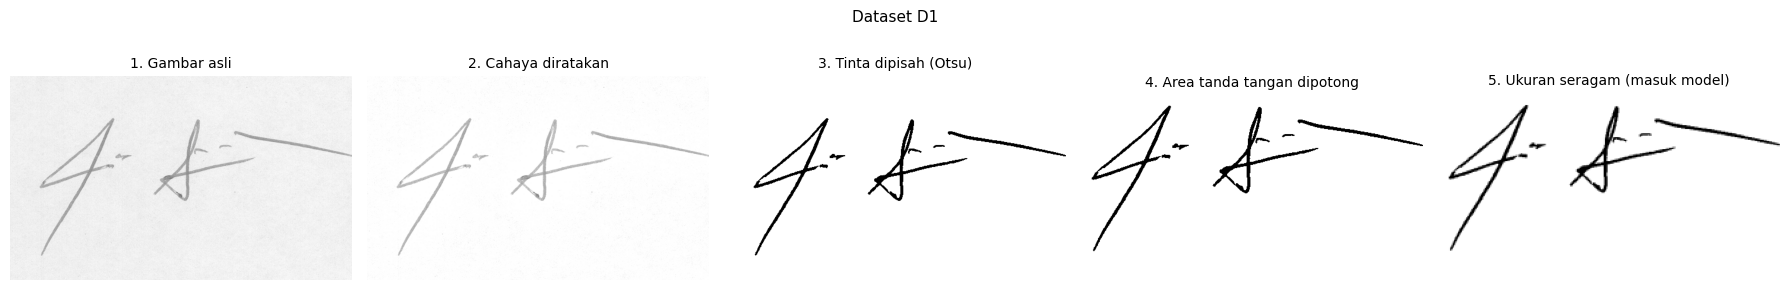

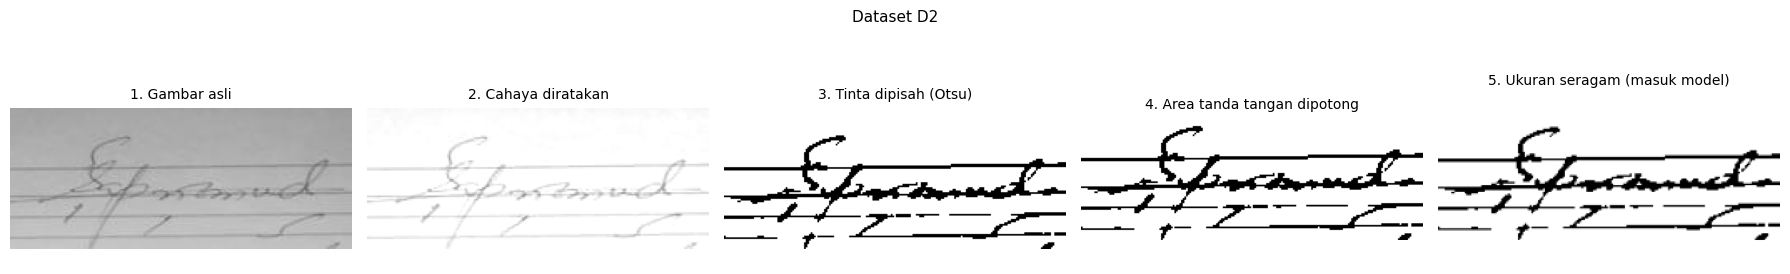

In [13]:
def contoh_langkah(baris, judul):
    gray0 = load_gray(baris.path)
    hasil_bin, langkah = preprocess_signature(gray0, "binary", return_steps=True)
    panel = [
        ("1. Gambar asli", langkah["asli"]),
        ("2. Cahaya diratakan", langkah["cahaya_rata"]),
        ("3. Tinta dipisah (Otsu)", 255 - langkah["mask"]),
        ("4. Area tanda tangan dipotong", 255 - langkah["potong"]),
        ("5. Ukuran seragam (masuk model)", 1 - hasil_bin),
    ]
    fig, axes = plt.subplots(1, len(panel), figsize=(18, 3.2))
    for ax, (jd, img) in zip(axes, panel):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255 if img.dtype == np.uint8 else 1)
        ax.set_title(jd, fontsize=10); ax.axis("off")
    fig.suptitle(judul, fontsize=11)
    plt.tight_layout()
    return fig

for tag in meta.dataset.unique():
    fig = contoh_langkah(meta[(meta.dataset == tag) & meta.is_genuine].iloc[0], f"Dataset {tag}")
    fig.savefig(os.path.join(FIG_DIR, f"01_langkah_pengolahan_{tag}.png"), dpi=150); plt.show()

## 6. Membagi data per orang

Orang di data latih **tidak pernah muncul** di data validasi maupun ujian. Jadi hasil ujian benar-benar menunjukkan kemampuan model pada tanda tangan orang yang belum pernah dilihat. Pembagian dilakukan terpisah untuk tiap dataset.

In [14]:
from sklearn.model_selection import train_test_split

SPLIT = {}
for tag in meta.dataset.unique():
    ws = sorted(meta[meta.dataset == tag].writer.unique())
    tr, tmp = train_test_split(ws, test_size=0.30, random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, random_state=SEED)
    SPLIT[tag] = {"train": tr, "val": va, "test": te}
    assert not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te))
    print(f"{tag}: orang train {len(tr)}, validasi {len(va)}, ujian {len(te)}")


def bagian(tag, nama):
    return meta[meta.writer.isin(SPLIT[tag][nama])]

D1: orang train 38, validasi 8, ujian 9
D2: orang train 84, validasi 18, ujian 18


## 7. Membuat pasangan gambar

Label pasangan: **0 = mirip** (sama-sama asli, orang yang sama), **1 = beda** (salah satunya palsu).

Pasangan "beda" ada dua jenis:
- `skilled_forgery`: tanda tangan asli vs tiruan orang yang sama (sulit)
- `random_forgery`: tanda tangan asli vs tanda tangan asli milik orang lain **di dataset yang sama** (lebih mudah)

Urutan gambar dalam pasangan diacak, supaya model tidak bisa menebak dari posisi. Orang lain hanya diambil dari dataset yang sama, supaya model tidak belajar jalan pintas "beda dataset berarti beda orang".

In [15]:
def create_pairs(df, n_pos_per_writer, seed):
    rng = random.Random(seed)
    ws = sorted(df.writer.unique())
    gen = {w: df.index[(df.writer == w) & df.is_genuine].tolist() for w in ws}
    frg = {w: df.index[(df.writer == w) & ~df.is_genuine].tolist() for w in ws}
    ds_of = df.groupby("writer").dataset.first().to_dict()
    rows, sudah = [], set()

    def add(a, b, label, tipe, w):
        if rng.random() < 0.5:
            a, b = b, a
        rows.append({"i1": a, "i2": b, "label": label, "pair_type": tipe, "writer": w, "dataset": ds_of[w]})

    for w in ws:
        g, f = gen[w], frg[w]
        if len(g) < 2:
            continue
        semua_pos = list(itertools.combinations(g, 2))
        pos = rng.sample(semua_pos, min(n_pos_per_writer, len(semua_pos)))
        for a, b in pos:
            add(a, b, 0, "genuine_pair", w)

        semua_skl = [(a, b) for a in g for b in f]
        n_skl = min(len(pos) // 2, len(semua_skl))
        for a, b in rng.sample(semua_skl, n_skl):
            add(a, b, 1, "skilled_forgery", w)

        lain = [x for x in ws if x != w and ds_of[x] == ds_of[w] and gen[x]]
        n_rnd, baru, coba = len(pos) - n_skl, 0, 0
        while baru < n_rnd and lain and coba < 50 * n_rnd:
            coba += 1
            o = rng.choice(lain)
            a, b = rng.choice(g), rng.choice(gen[o])
            kunci = (min(a, b), max(a, b))
            if kunci in sudah:
                continue
            sudah.add(kunci)
            add(a, b, 1, "random_forgery", w)
            baru += 1
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)


PAIRS = {}
PAIRS_EVAL = 20 if QUICK_TEST else 100     # jumlah pasangan per orang untuk validasi dan ujian (tetap, supaya hasil tidak berubah walau data latih dikecilkan)
for tag in SPLIT:
    PAIRS[(tag, "train")] = create_pairs(bagian(tag, "train"), PAIRS_PER_WRITER, SEED)
    PAIRS[(tag, "val")]   = create_pairs(bagian(tag, "val"),   PAIRS_EVAL, SEED + 1)
    PAIRS[(tag, "test")]  = create_pairs(bagian(tag, "test"),  PAIRS_EVAL, SEED + 2)

for (tag, nama), p in PAIRS.items():
    print(f"{tag} {nama:5s} total {len(p):6d} | mirip {int((p.label == 0).sum()):5d} | beda {int((p.label == 1).sum()):5d} | {p.pair_type.value_counts().to_dict()}")

D1 train total   9120 | mirip  4560 | beda  4560 | {'genuine_pair': 4560, 'random_forgery': 2280, 'skilled_forgery': 2280}
D1 val   total   1600 | mirip   800 | beda   800 | {'genuine_pair': 800, 'skilled_forgery': 400, 'random_forgery': 400}
D1 test  total   1800 | mirip   900 | beda   900 | {'genuine_pair': 900, 'skilled_forgery': 450, 'random_forgery': 450}
D2 train total   8626 | mirip  4313 | beda  4313 | {'genuine_pair': 4313, 'random_forgery': 4313}
D2 val   total   1866 | mirip   933 | beda   933 | {'random_forgery': 933, 'genuine_pair': 933}
D2 test  total   1824 | mirip   912 | beda   912 | {'genuine_pair': 912, 'random_forgery': 912}


## 8. Model Siamese CNN

Satu jaringan CNN yang sama dipakai untuk dua gambar, hasilnya dua "sidik jari" (embedding). Makin dekat jarak keduanya, makin mirip tanda tangannya.
Pembaruan dibanding versi awal: BatchNorm, embedding dinormalisasi (L2) supaya margin bermakna, augmentasi ringan saat training (geser, putar, zoom kecil, **tanpa flip**), dan layer jarak yang aman disimpan/dimuat.

In [16]:
from tensorflow.keras import layers, Model, Input


def build_embedding_net(embedding_dim=64):
    inp = Input(shape=(IMG_H, IMG_W, 1), name="signature")
    x = inp
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(embedding_dim)(x)
    x = layers.UnitNormalization(name="l2_norm")(x)
    return Model(inp, x, name="embedding_net")


@tf.keras.utils.register_keras_serializable(package="ttd")
class EuclideanDistance(layers.Layer):
    def call(self, inputs):
        a, b = inputs
        kuadrat = tf.reduce_sum(tf.square(a - b), axis=1, keepdims=True)
        return tf.sqrt(tf.maximum(kuadrat, 1e-9))


def build_siamese(margin=MARGIN):
    base = build_embedding_net()
    augment = tf.keras.Sequential([
        layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0),
        layers.RandomRotation(0.02, fill_mode="constant", fill_value=0.0),
        layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0),
    ], name="augment")   # hanya aktif saat training

    in1 = Input(shape=(IMG_H, IMG_W, 1), name="image1")
    in2 = Input(shape=(IMG_H, IMG_W, 1), name="image2")
    e1 = base(augment(in1))
    e2 = base(augment(in2))
    dist = EuclideanDistance(name="distance")([e1, e2])
    model = Model([in1, in2], dist, name="siamese_cnn")

    def contrastive_loss(y_true, y_pred):
        y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
        y_pred = tf.reshape(y_pred, [-1])
        mirip = (1.0 - y_true) * tf.square(y_pred)
        beda = y_true * tf.square(tf.maximum(margin - y_pred, 0.0))
        return tf.reduce_mean(mirip + beda)

    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE), loss=contrastive_loss)
    return model, base


class PairSequence(tf.keras.utils.Sequence):
    """Menyuplai pasangan gambar ke model, batch demi batch."""

    def __init__(self, images, i1, i2, y, batch_size, shuffle=False, seed=0):
        super().__init__()
        self.images, self.i1, self.i2 = images, np.asarray(i1), np.asarray(i2)
        self.y = np.asarray(y, dtype=np.float32)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.rng = np.random.default_rng(seed)
        self.order = np.arange(len(self.y))
        if shuffle:
            self.rng.shuffle(self.order)

    def __len__(self):
        return int(np.ceil(len(self.y) / self.batch_size))

    def __getitem__(self, idx):
        sel = self.order[idx * self.batch_size:(idx + 1) * self.batch_size]
        x = {"image1": self.images[self.i1[sel]].astype(np.float32),
             "image2": self.images[self.i2[sel]].astype(np.float32)}
        return x, self.y[sel]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)


def embed_images(base, images, batch=128):
    out = [base.predict(images[i:i + batch].astype(np.float32), verbose=0) for i in range(0, len(images), batch)]
    return np.concatenate(out)


tmp_model, tmp_base = build_siamese()
tmp_base.summary()
del tmp_model, tmp_base

I0000 00:00:1792974009.419730      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792974009.425340      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "embedding_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ signature (InputLayer)          │ (None, 128, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 256, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 128, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 128, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 32, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 16, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_norm (UnitNormalization)     │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,591,968 (17.52 MB)

 Trainable params: 4,591,008 (17.51 MB)

 Non-trainable params: 960 (3.75 KB)

## 9. Fungsi penilaian

- **AUC**: seberapa baik model memisahkan asli dan palsu di semua batas (1.0 = sempurna, 0.5 = menebak).
- **EER**: titik di mana tanda tangan asli yang ditolak (FRR) sama banyak dengan palsu yang lolos (FAR). Makin kecil makin bagus.
- **FAR**: palsu yang lolos dianggap asli. **FRR**: asli yang salah ditolak.

Batas jarak **dipilih di data validasi** (titik EER), lalu dipakai apa adanya di data ujian. Data ujian tidak dipakai untuk memilih apa pun.

In [17]:
from sklearn.metrics import (roc_curve, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)


def eer_and_threshold(y, d):
    fpr, tpr, thr = roc_curve(y, d)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[i] + fnr[i]) / 2), float(thr[i])


def metrics_at(d, y, thr, types=None):
    """Nilai untuk satu set pasangan dengan batas jarak yang sudah ditentukan."""
    d, y = np.asarray(d), np.asarray(y)
    pred = (d >= thr).astype(int)           # 1 = diduga palsu
    eer, _ = eer_and_threshold(y, d)
    hasil = {
        "auc": float(roc_auc_score(y, d)),
        "eer": eer,
        "accuracy": float(accuracy_score(y, pred)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "FRR": float(np.mean(pred[y == 0] == 1)),
        "FAR": float(np.mean(pred[y == 1] == 0)),
    }
    if types is not None:
        types = np.asarray(types)
        for tipe in ("skilled_forgery", "random_forgery"):
            m = types == tipe
            hasil[f"FAR_{tipe}"] = float(np.mean(pred[m] == 0)) if m.any() else float("nan")
    hasil["confusion_matrix"] = confusion_matrix(y, pred, labels=[0, 1]).tolist()
    return hasil


def jarak(emb, pairs):
    return np.linalg.norm(emb[pairs.i1.values] - emb[pairs.i2.values], axis=1)


def gabung_pairs(*daftar):
    return pd.concat(daftar, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)

## 10. Tes cepat (±1 menit)

Memastikan model, data, dan training jalan sebelum training panjang dimulai.

In [18]:
_m = MODES_TO_TRY[0]
_p = PAIRS[("D1", "train")]
_model, _base = build_siamese()
_seq = PairSequence(IMAGES[_m], _p.i1[:64], _p.i2[:64], _p.label[:64], 16, shuffle=True)
_model.fit(_seq, epochs=1, verbose=0)
_emb = embed_images(_base, IMAGES[_m][:8])
assert _emb.shape == (8, 64), _emb.shape
print("Tes cepat berhasil. Model, data, dan training berjalan normal.")
del _model, _base, _seq, _emb, _p

Tes cepat berhasil. Model, data, dan training berjalan normal.


I0000 00:00:1792974024.309480     168 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


## 11. Percobaan A: latih di dataset 1, bandingkan cara pengolahan citra

Untuk setiap cara pengolahan citra dilatih satu model. Lalu diuji di:
- **D1 ujian**: orang baru dari dataset yang sama
- **D2 ujian (lintas dataset)**: orang baru dari dataset lain yang **belum pernah dilihat sama sekali**. Ini ukuran kemampuan model menghadapi data yang berbeda.

In [19]:
def train_model(mode, train_pairs, val_pairs, nama):
    print("\n" + "=" * 60 + f"\n{nama} | pengolahan citra: {mode}\n" + "=" * 60)
    images = IMAGES[mode]
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model, base = build_siamese()
    train_seq = PairSequence(images, train_pairs.i1, train_pairs.i2, train_pairs.label, BATCH_SIZE, shuffle=True, seed=SEED)
    val_seq = PairSequence(images, val_pairs.i1, val_pairs.i2, val_pairs.label, BATCH_SIZE)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]
    t0 = time.time()
    hist = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS, callbacks=callbacks, verbose=2)
    menit = (time.time() - t0) / 60
    emb = embed_images(base, images)
    return base, hist.history, emb, round(menit, 1)


def nilai_model(emb, val_pairs, tests):
    """Batas dari validasi. tests: dict nama -> pasangan. return: threshold, val_eer, dict nama -> metrik."""
    d_val = jarak(emb, val_pairs)
    val_eer, thr = eer_and_threshold(val_pairs.label.values, d_val)
    out = {}
    for nama, p in tests.items():
        out[nama] = metrics_at(jarak(emb, p), p.label.values, thr, p.pair_type.values)
    return thr, val_eer, out


TESTS = {"D1": PAIRS[("D1", "test")]}
if HAS_D2:
    TESTS["D2"] = PAIRS[("D2", "test")]

RES_A = {}
for m in MODES_TO_TRY:
    base, hist, emb, menit = train_model(m, PAIRS[("D1", "train")], PAIRS[("D1", "val")], "Percobaan A (latih D1)")
    thr, val_eer, out = nilai_model(emb, PAIRS[("D1", "val")], TESTS)
    RES_A[m] = {"base": base, "history": hist, "emb": emb, "thr": thr, "val_eer": val_eer, "metrics": out,
                "epochs": len(hist["loss"]), "menit": menit}
    ringkas = "  ".join(f"[{k}] AUC={v['auc']:.3f} EER={v['eer']:.3f} Akurasi={v['accuracy']:.3f}" for k, v in out.items())
    print(f"\nHasil {m}: {ringkas}")


Percobaan A (latih D1) | pengolahan citra: raw
Epoch 1/8
143/143 - 51s - 354ms/step - loss: 0.1158 - val_loss: 0.4676 - learning_rate: 3.0000e-04
Epoch 2/8
143/143 - 44s - 309ms/step - loss: 0.0640 - val_loss: 0.1734 - learning_rate: 3.0000e-04
Epoch 3/8
143/143 - 47s - 329ms/step - loss: 0.0511 - val_loss: 0.0770 - learning_rate: 3.0000e-04
Epoch 4/8
143/143 - 47s - 330ms/step - loss: 0.0422 - val_loss: 0.0784 - learning_rate: 3.0000e-04
Epoch 5/8
143/143 - 47s - 331ms/step - loss: 0.0375 - val_loss: 0.0815 - learning_rate: 3.0000e-04
Epoch 6/8
143/143 - 47s - 329ms/step - loss: 0.0311 - val_loss: 0.0856 - learning_rate: 1.5000e-04

Hasil raw: [D1] AUC=0.940 EER=0.138 Akurasi=0.869  [D2] AUC=0.747 EER=0.325 Akurasi=0.565

Percobaan A (latih D1) | pengolahan citra: binary
Epoch 1/8
143/143 - 51s - 360ms/step - loss: 0.1841 - val_loss: 0.3792 - learning_rate: 3.0000e-04
Epoch 2/8
143/143 - 45s - 318ms/step - loss: 0.1095 - val_loss: 0.1262 - learning_rate: 3.0000e-04
Epoch 3/8
143/143 

## 12. Percobaan B: latih gabungan dataset 1 + 2

Memakai cara pengolahan citra terbaik dari percobaan A (dipilih dari data **validasi**, bukan ujian). Kalau dataset 2 tidak tersedia, bagian ini dilewati.

In [20]:
# Pilih cara pengolahan citra dari data VALIDASI: rata-rata EER di D1-val dan (kalau ada) D2-val.
# Dengan begitu cara yang hanya unggul karena kebiasaan teknis satu dataset tidak otomatis terpilih.
for m, r in RES_A.items():
    r["val_eer_d2"] = None
    if HAS_D2:
        pv = PAIRS[("D2", "val")]
        r["val_eer_d2"] = eer_and_threshold(pv.label.values, jarak(r["emb"], pv))[0]
    r["skor_pilih"] = r["val_eer"] if r["val_eer_d2"] is None else (r["val_eer"] + r["val_eer_d2"]) / 2
    print(f"{m:7s} EER val D1 = {r['val_eer']:.3f}" + (f" | EER val D2 = {r['val_eer_d2']:.3f}" if r["val_eer_d2"] is not None else "") + f" | skor pilih = {r['skor_pilih']:.3f}")
BEST_MODE = min(RES_A, key=lambda m: RES_A[m]["skor_pilih"])
if FORCE_MODE:
    assert FORCE_MODE in RES_A, f"FORCE_MODE harus salah satu dari {list(RES_A)}"
    BEST_MODE = FORCE_MODE
    print("Cara pengolahan citra DIPAKSA oleh pengaturan:", BEST_MODE)
print("Cara pengolahan citra terpilih:", BEST_MODE)

RES_B = None
if HAS_D2:
    tr = gabung_pairs(PAIRS[("D1", "train")], PAIRS[("D2", "train")])
    va = gabung_pairs(PAIRS[("D1", "val")], PAIRS[("D2", "val")])
    base, hist, emb, menit = train_model(BEST_MODE, tr, va, "Percobaan B (latih gabungan D1+D2)")
    thr, val_eer, out = nilai_model(emb, va, TESTS)
    RES_B = {"base": base, "history": hist, "emb": emb, "thr": thr, "val_eer": val_eer, "metrics": out,
             "epochs": len(hist["loss"]), "menit": menit, "val_pairs": va, "train_pairs": tr}
    print("\nHasil gabungan:", "  ".join(f"[{k}] AUC={v['auc']:.3f} EER={v['eer']:.3f} Akurasi={v['accuracy']:.3f}" for k, v in out.items()))

# Model yang dipakai untuk bagian berikutnya dan untuk demo:
if RES_B is not None:
    FINAL, FINAL_NAME = RES_B, "gabungan D1+D2"
    FINAL_VAL = RES_B["val_pairs"]
else:
    FINAL, FINAL_NAME = RES_A[BEST_MODE], f"D1 saja ({BEST_MODE})"
    FINAL_VAL = PAIRS[("D1", "val")]
FINAL_MODE, FINAL_THR = BEST_MODE, FINAL["thr"]
print("Model akhir:", FINAL_NAME, "| batas jarak:", round(FINAL_THR, 4))

raw     EER val D1 = 0.074 | EER val D2 = 0.260 | skor pilih = 0.167
binary  EER val D1 = 0.136 | EER val D2 = 0.290 | skor pilih = 0.213
Cara pengolahan citra DIPAKSA oleh pengaturan: binary
Cara pengolahan citra terpilih: binary

Percobaan B (latih gabungan D1+D2) | pengolahan citra: binary
Epoch 1/8
278/278 - 96s - 345ms/step - loss: 0.1820 - val_loss: 0.1444 - learning_rate: 3.0000e-04
Epoch 2/8
278/278 - 90s - 323ms/step - loss: 0.1219 - val_loss: 0.1307 - learning_rate: 3.0000e-04
Epoch 3/8
278/278 - 90s - 322ms/step - loss: 0.1000 - val_loss: 0.1267 - learning_rate: 3.0000e-04
Epoch 4/8
278/278 - 90s - 322ms/step - loss: 0.0849 - val_loss: 0.1315 - learning_rate: 3.0000e-04
Epoch 5/8
278/278 - 90s - 323ms/step - loss: 0.0728 - val_loss: 0.1276 - learning_rate: 3.0000e-04
Epoch 6/8
278/278 - 90s - 323ms/step - loss: 0.0627 - val_loss: 0.1319 - learning_rate: 1.5000e-04

Hasil gabungan: [D1] AUC=0.932 EER=0.153 Akurasi=0.853  [D2] AUC=0.900 EER=0.181 Akurasi=0.816
Model akhir: gab

## 13. Tabel hasil utama

In [21]:
baris = []
for m, r in RES_A.items():
    row = {"percobaan": f"A: latih D1 | {m}", "val_eer": r["val_eer"], "batas": r["thr"], "epoch": r["epochs"], "menit": r["menit"]}
    for k, v in r["metrics"].items():
        for kol in ("auc", "eer", "accuracy", "FAR", "FRR"):
            row[f"{k}_{kol}"] = v[kol]
        row[f"{k}_FAR_skilled"] = v.get("FAR_skilled_forgery", np.nan)
    baris.append(row)
if RES_B is not None:
    row = {"percobaan": f"B: latih D1+D2 | {BEST_MODE}", "val_eer": RES_B["val_eer"], "batas": RES_B["thr"],
           "epoch": RES_B["epochs"], "menit": RES_B["menit"]}
    for k, v in RES_B["metrics"].items():
        for kol in ("auc", "eer", "accuracy", "FAR", "FRR"):
            row[f"{k}_{kol}"] = v[kol]
        row[f"{k}_FAR_skilled"] = v.get("FAR_skilled_forgery", np.nan)
    baris.append(row)

TABEL_UTAMA = pd.DataFrame(baris).set_index("percobaan")
display(TABEL_UTAMA.round(4).T)
TABEL_UTAMA.round(4).to_csv(os.path.join(OUT_DIR, "tabel_utama.csv"))

percobaan,A: latih D1 | raw,A: latih D1 | binary,B: latih D1+D2 | binary
val_eer,0.0737,0.1362,0.1740
batas,0.4389,0.5511,0.4811
epoch,6.0000,8.0000,6.0000
menit,4.7000,6.2000,9.1000
D1_auc,0.9402,0.8925,0.9321
D1_eer,0.1383,0.2011,0.1533
D1_accuracy,0.8689,0.7872,0.8528
D1_FAR,0.1478,0.1489,0.1078
D1_FRR,0.1144,0.2767,0.1867
D1_FAR_skilled,0.0000,0.2111,0.1644


### Grafik untuk laporan

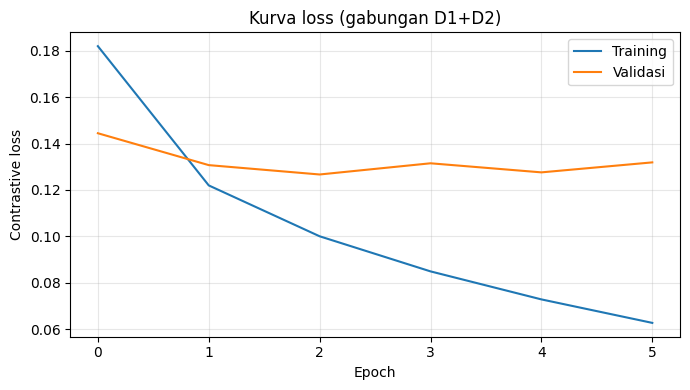

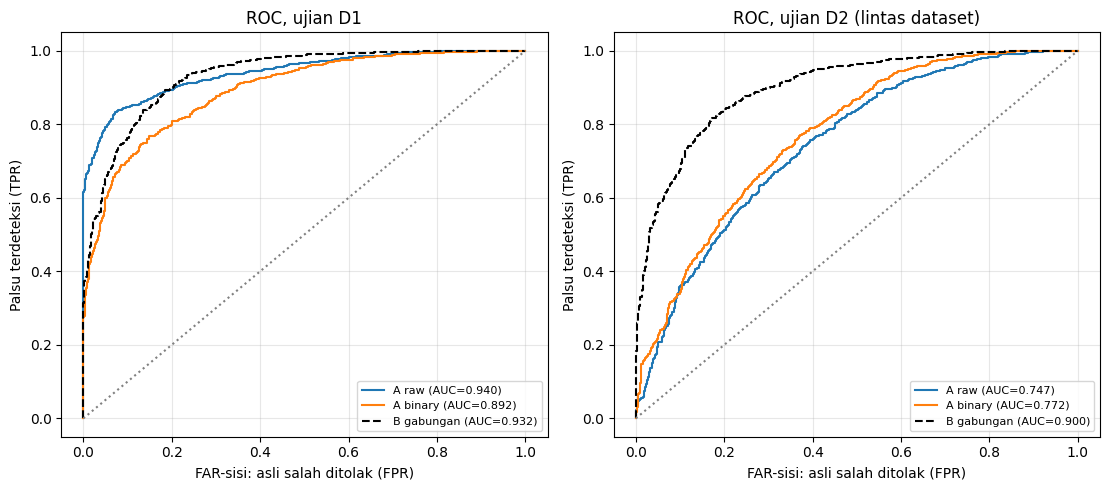

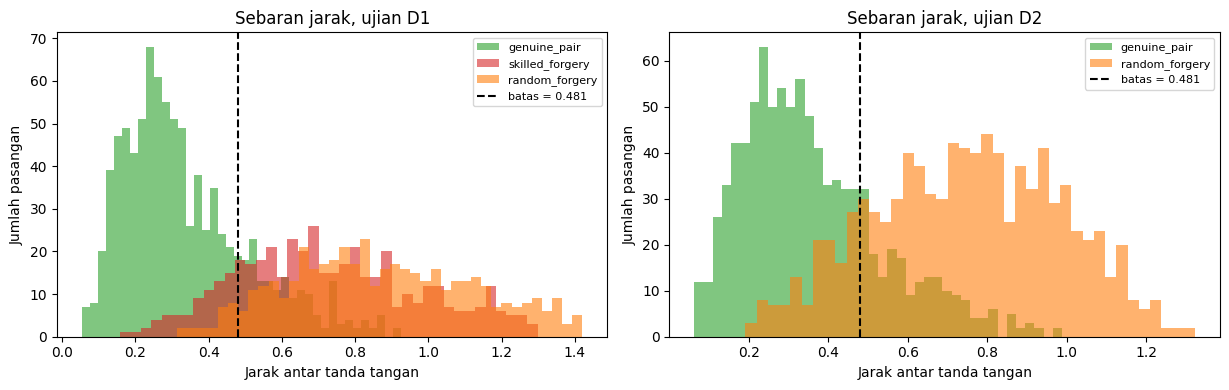

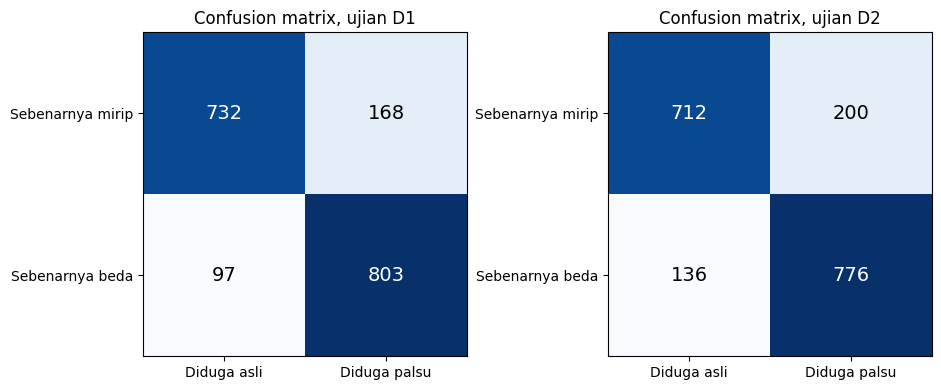

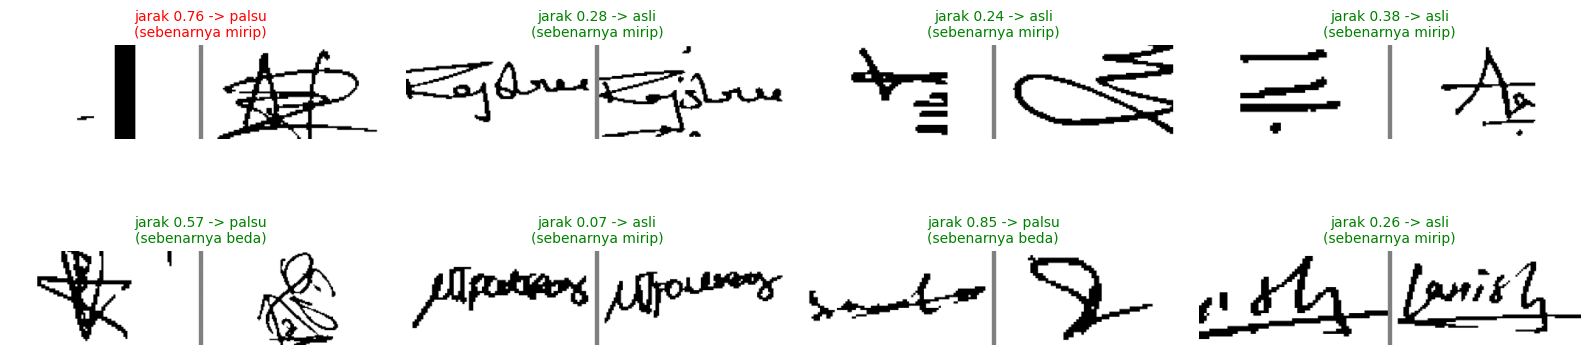

In [22]:
test_names = list(TESTS)
h = FINAL["history"]
plt.figure(figsize=(7, 4))
plt.plot(h["loss"], label="Training"); plt.plot(h["val_loss"], label="Validasi")
plt.xlabel("Epoch"); plt.ylabel("Contrastive loss"); plt.title(f"Kurva loss ({FINAL_NAME})")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "02_kurva_loss.png"), dpi=150); plt.show()

# ROC semua cara pengolahan citra (percobaan A), satu panel per dataset ujian
fig, axes = plt.subplots(1, len(test_names), figsize=(5.6 * len(test_names), 5), squeeze=False)
for ax, tk in zip(axes[0], test_names):
    p = TESTS[tk]
    for m, r in RES_A.items():
        fpr, tpr, _ = roc_curve(p.label.values, jarak(r["emb"], p))
        ax.plot(fpr, tpr, label=f"A {m} (AUC={r['metrics'][tk]['auc']:.3f})")
    if RES_B is not None:
        fpr, tpr, _ = roc_curve(p.label.values, jarak(RES_B["emb"], p))
        ax.plot(fpr, tpr, "k--", label=f"B gabungan (AUC={RES_B['metrics'][tk]['auc']:.3f})")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set_xlabel("FAR-sisi: asli salah ditolak (FPR)"); ax.set_ylabel("Palsu terdeteksi (TPR)")
    ax.set_title(f"ROC, ujian {tk}" + (" (lintas dataset)" if tk == "D2" else ""))
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "03_kurva_roc.png"), dpi=150); plt.show()

# Sebaran jarak model akhir
fig, axes = plt.subplots(1, len(test_names), figsize=(6.2 * len(test_names), 4), squeeze=False)
for ax, tk in zip(axes[0], test_names):
    p = TESTS[tk]; d = jarak(FINAL["emb"], p)
    for tipe, warna in (("genuine_pair", "tab:green"), ("skilled_forgery", "tab:red"), ("random_forgery", "tab:orange")):
        mk = p.pair_type.values == tipe
        if mk.any():
            ax.hist(d[mk], bins=40, alpha=.6, label=tipe, color=warna)
    ax.axvline(FINAL_THR, color="black", linestyle="--", label=f"batas = {FINAL_THR:.3f}")
    ax.set_xlabel("Jarak antar tanda tangan"); ax.set_ylabel("Jumlah pasangan"); ax.set_title(f"Sebaran jarak, ujian {tk}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "04_sebaran_jarak.png"), dpi=150); plt.show()

# Confusion matrix model akhir
fig, axes = plt.subplots(1, len(test_names), figsize=(4.8 * len(test_names), 4), squeeze=False)
for ax, tk in zip(axes[0], test_names):
    cm = np.array(FINAL["metrics"][tk]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Diduga asli", "Diduga palsu"]); ax.set_yticks([0, 1], ["Sebenarnya mirip", "Sebenarnya beda"])
    ax.set_title(f"Confusion matrix, ujian {tk}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "05_confusion_matrix.png"), dpi=150); plt.show()

# Contoh pasangan (model akhir)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 5))
pk = TESTS[test_names[-1]]
img_final = IMAGES[FINAL_MODE]
for ax, k in zip(axes.ravel(), rng.choice(len(pk), 8, replace=False)):
    r = pk.iloc[k]
    gabung = np.hstack([img_final[r.i1, :, :, 0], np.ones((IMG_H, 6)) * 0.5, img_final[r.i2, :, :, 0]]).astype(np.float32)
    d = float(np.linalg.norm(FINAL["emb"][r.i1] - FINAL["emb"][r.i2]))
    pred_palsu = d >= FINAL_THR
    benar = pred_palsu == bool(r.label)
    ax.imshow(1 - gabung, cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"jarak {d:.2f} -> {'palsu' if pred_palsu else 'asli'}\n(sebenarnya {'beda' if r.label else 'mirip'})",
                 fontsize=10, color="green" if benar else "red")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "06_contoh_pasangan.png"), dpi=150); plt.show()

In [23]:
# Nilai awal supaya sel penyimpanan tetap bisa jalan walaupun satu bagian eksperimen gagal
import traceback
MULTI, GOYANG, FORENSIK_BATAS, TABEL_FUSI = {}, {}, {}, pd.DataFrame()
RAGU_Z = RAGU_MARGIN = None
sc_u = lr_u = None
SKENARIO = {}
GAGAL = []

## 14. Uji tahan foto HP

Di kehidupan nyata, tanda tangan sering difoto dari HP: ada bayangan, agak buram, miring, redup, atau berbintik. Di sini tanda tangan yang diperiksa (sisi kedua tiap pasangan) **sengaja dirusak** dengan gangguan buatan, lalu dilihat seberapa tahan tiap cara pengolahan citra. Batas jarak tidak diubah.

Ini pembuktian bahwa pengolahan citra benar-benar berguna, bukan sekadar tahap bersih-bersih.

EER (makin kecil makin bagus), model dilatih di D1, diuji di D1 dengan gangguan:


,raw,binary,B_binary
bersih,0.1383,0.2011,0.1533
bayangan,0.5483,0.2017,0.1533
buram,0.1622,0.2778,0.2000
miring,0.1322,0.2044,0.1583
redup,0.5567,0.1983,0.1522
noise,0.2372,0.1967,0.1544
foto_hp,0.5544,0.2256,0.1711


Akurasi pada batas tetap:


,raw,binary,B_binary
bersih,0.8689,0.7872,0.8528
bayangan,0.5000,0.7883,0.8522
buram,0.8189,0.7178,0.7983
miring,0.8683,0.7767,0.8472
redup,0.4983,0.7867,0.8528
noise,0.7628,0.7911,0.8511
foto_hp,0.5000,0.7589,0.8172


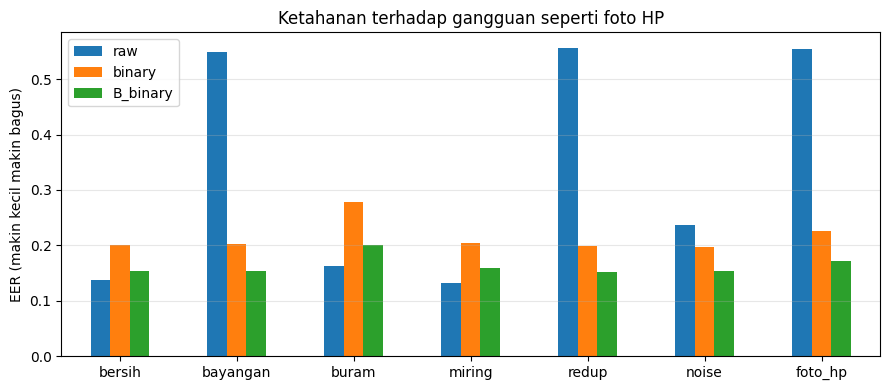

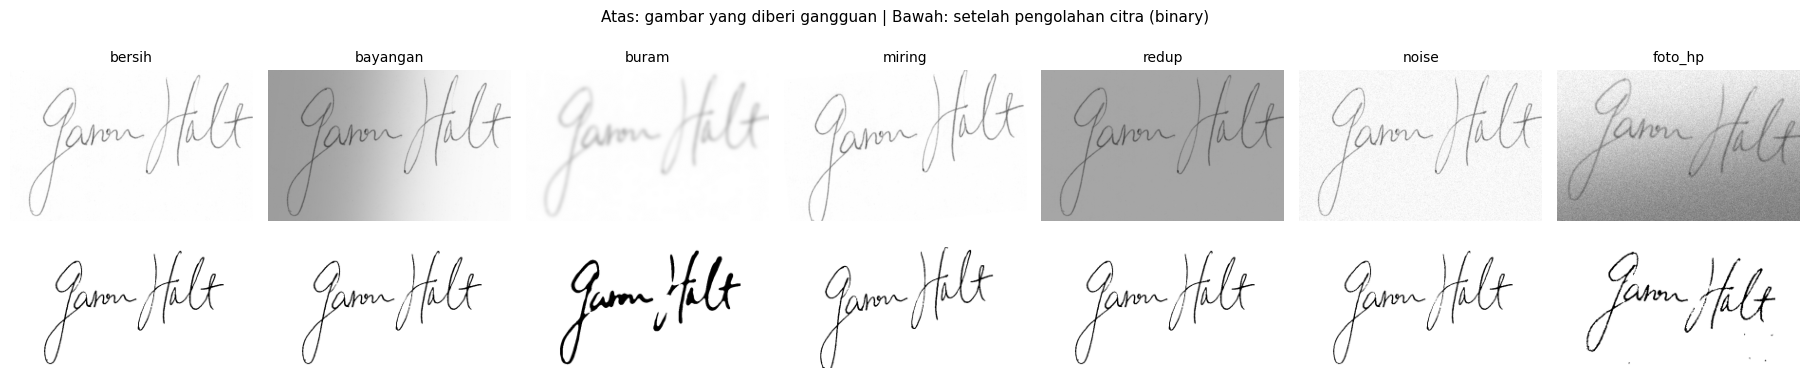

In [24]:
try:
    tp = PAIRS[("D1", "test")]
    uniq = np.unique(np.concatenate([tp.i1.values, tp.i2.values]))
    pos = {int(u): k for k, u in enumerate(uniq)}
    gray_cache = {int(u): load_gray(meta.path[u]) for u in uniq}

    PERT = {}
    for c in KONDISI:
        rng_c = np.random.default_rng(SEED + sum(map(ord, c)))
        kumpul = {m: [] for m in MODES_TO_TRY}
        for u in uniq:
            a, _ = preprocess_all(KONDISI[c](gray_cache[int(u)], rng_c), MODES_TO_TRY)
            for m in MODES_TO_TRY:
                kumpul[m].append(a[m].astype(np.float16))
        PERT[c] = {m: np.stack(v)[..., None] for m, v in kumpul.items()}

    i1, i2 = tp.i1.values, tp.i2.values
    idx2 = np.array([pos[int(i)] for i in i2])
    y = tp.label.values
    ROB = {}
    for m in MODES_TO_TRY:
        emb_clean, thr_m = RES_A[m]["emb"], RES_A[m]["thr"]
        for c in ["bersih"] + list(KONDISI):
            if c == "bersih":
                d = np.linalg.norm(emb_clean[i1] - emb_clean[i2], axis=1)
            else:
                ep = embed_images(RES_A[m]["base"], PERT[c][m])
                d = np.linalg.norm(emb_clean[i1] - ep[idx2], axis=1)
            mt = metrics_at(d, y, thr_m)
            ROB[(c, m)] = {"auc": mt["auc"], "eer": mt["eer"], "accuracy": mt["accuracy"]}

    # model akhir (gabungan D1+D2) juga diuji dengan gangguan yang sama
    KOLOM_ROB = list(MODES_TO_TRY)
    if RES_B is not None:
        try:
            nama_b = "B_" + FINAL_MODE
            emb_b, thr_b = RES_B["emb"], RES_B["thr"]
            for c in ["bersih"] + list(KONDISI):
                if c == "bersih":
                    d = np.linalg.norm(emb_b[i1] - emb_b[i2], axis=1)
                else:
                    ep = embed_images(RES_B["base"], PERT[c][FINAL_MODE])
                    d = np.linalg.norm(emb_b[i1] - ep[idx2], axis=1)
                mt = metrics_at(d, y, thr_b)
                ROB[(c, nama_b)] = {"auc": mt["auc"], "eer": mt["eer"], "accuracy": mt["accuracy"]}
            KOLOM_ROB.append(nama_b)
        except Exception:
            traceback.print_exc()
    rob_eer = pd.DataFrame({m: {c: ROB[(c, m)]["eer"] for c in ["bersih"] + list(KONDISI)} for m in KOLOM_ROB})
    rob_acc = pd.DataFrame({m: {c: ROB[(c, m)]["accuracy"] for c in ["bersih"] + list(KONDISI)} for m in KOLOM_ROB})
    print("EER (makin kecil makin bagus), model dilatih di D1, diuji di D1 dengan gangguan:")
    display(rob_eer.round(4))
    print("Akurasi pada batas tetap:")
    display(rob_acc.round(4))
    rob_eer.round(4).to_csv(os.path.join(OUT_DIR, "tabel_ketahanan_eer.csv"))
    rob_acc.round(4).to_csv(os.path.join(OUT_DIR, "tabel_ketahanan_akurasi.csv"))

    # grafik
    ax = rob_eer.plot(kind="bar", figsize=(9, 4))
    ax.set_ylabel("EER (makin kecil makin bagus)"); ax.set_title("Ketahanan terhadap gangguan seperti foto HP")
    plt.xticks(rotation=0); plt.grid(axis="y", alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "07_ketahanan_foto.png"), dpi=150); plt.show()

    # contoh gangguan + hasil pengolahan citranya
    contoh = gray_cache[int(uniq[0])]
    rg = np.random.default_rng(1)
    kolom = ["bersih"] + list(KONDISI)
    fig, axes = plt.subplots(2, len(kolom), figsize=(2.6 * len(kolom), 4.2))
    for j, c in enumerate(kolom):
        g = contoh if c == "bersih" else KONDISI[c](contoh, rg)
        axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(c, fontsize=10); axes[0, j].axis("off")
        axes[1, j].imshow(1 - preprocess_signature(g, "binary"), cmap="gray", vmin=0, vmax=1); axes[1, j].axis("off")
    axes[0, 0].set_ylabel("gambar"); plt.suptitle("Atas: gambar yang diberi gangguan | Bawah: setelah pengolahan citra (binary)", fontsize=11)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_contoh_gangguan.png"), dpi=150); plt.show()
except Exception:
    traceback.print_exc()
    GAGAL.append('uji tahan foto')

## 15. Banyak pembanding

Satu orang tidak menandatangani persis sama setiap kali, jadi membandingkan dengan **beberapa** tanda tangan asli biasanya lebih akurat. Skor = rata-rata jarak ke k pembanding. Diulang beberapa kali dengan pembanding yang diacak, hasilnya dirata-rata. Memakai model akhir.

,dataset,k_pembanding,auc,auc_std,eer,eer_std
0,D1,1,0.9366,0.0102,0.1477,0.0179
1,D1,2,0.9478,0.0085,0.1250,0.0178
2,D1,3,0.9508,0.0064,0.1269,0.0082
3,D1,5,0.9549,0.0027,0.1192,0.0085
4,D2,1,0.8967,0.0183,0.1915,0.0243
5,D2,2,0.9214,0.0089,0.1595,0.0090
6,D2,3,0.9249,0.0141,0.1572,0.0230
7,D2,5,0.9454,0.0093,0.1256,0.0126


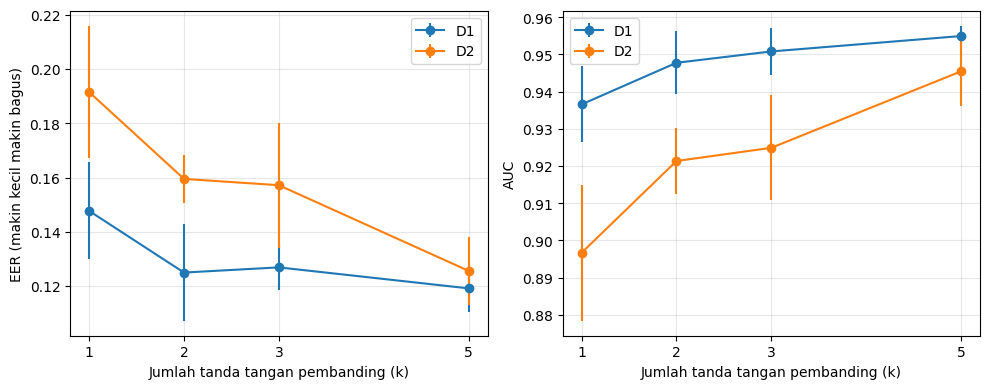

In [25]:
try:
    def multi_ref(df, emb, ks=(1, 2, 3, 5), trials=8, seed=SEED):
        rng = np.random.default_rng(seed)
        ws = sorted(df.writer.unique())
        gen = {w: df.index[(df.writer == w) & df.is_genuine].to_numpy() for w in ws}
        frg = {w: df.index[(df.writer == w) & ~df.is_genuine].to_numpy() for w in ws}
        hasil = {}
        for k in ks:
            aucs, eers = [], []
            for _ in range(trials):
                S, Y = [], []
                for w in ws:
                    g = gen[w]
                    if len(g) < k + 1:
                        continue
                    refs = rng.choice(g, k, replace=False)
                    qg = np.setdiff1d(g, refs)
                    lain = np.concatenate([gen[x] for x in ws if x != w]) if len(ws) > 1 else np.array([], int)
                    oth = rng.choice(lain, min(len(qg), len(lain)), replace=False) if len(lain) else lain
                    q = np.concatenate([qg, frg[w], oth]).astype(int)
                    yy = np.concatenate([np.zeros(len(qg)), np.ones(len(frg[w])), np.ones(len(oth))])
                    S.append(np.linalg.norm(emb[q][:, None, :] - emb[refs][None, :, :], axis=2).mean(1)); Y.append(yy)
                if not S:
                    continue
                S, Y = np.concatenate(S), np.concatenate(Y)
                if len(np.unique(Y)) < 2:
                    continue
                aucs.append(roc_auc_score(Y, S)); eers.append(eer_and_threshold(Y, S)[0])
            if aucs:
                hasil[k] = {"auc": float(np.mean(aucs)), "auc_std": float(np.std(aucs)),
                            "eer": float(np.mean(eers)), "eer_std": float(np.std(eers))}
        return hasil


    MULTI = {}
    for tk in TESTS:
        MULTI[tk] = multi_ref(bagian(tk, "test"), FINAL["emb"])
    baris = [{"dataset": tk, "k_pembanding": k, **v} for tk, d in MULTI.items() for k, v in d.items()]
    TABEL_MULTI = pd.DataFrame(baris)
    display(TABEL_MULTI.round(4))
    TABEL_MULTI.round(4).to_csv(os.path.join(OUT_DIR, "tabel_banyak_pembanding.csv"), index=False)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for tk, d in MULTI.items():
        ks_ = sorted(d)
        axes[0].errorbar(ks_, [d[k]["eer"] for k in ks_], yerr=[d[k]["eer_std"] for k in ks_], marker="o", label=tk)
        axes[1].errorbar(ks_, [d[k]["auc"] for k in ks_], yerr=[d[k]["auc_std"] for k in ks_], marker="o", label=tk)
    axes[0].set_ylabel("EER (makin kecil makin bagus)"); axes[1].set_ylabel("AUC")
    for a in axes:
        a.set_xlabel("Jumlah tanda tangan pembanding (k)"); a.grid(alpha=.3); a.legend(); a.set_xticks(sorted({k for d in MULTI.values() for k in d}))
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_banyak_pembanding.png"), dpi=150); plt.show()
except Exception:
    traceback.print_exc()
    GAGAL.append('banyak pembanding')

## 16. Uji goyang: seberapa yakin keputusannya?

Setiap tanda tangan diperiksa beberapa kali dalam versi yang **digeser, diputar, dan diperbesar sedikit**. Kalau semua versi memberi keputusan yang sama, model yakin. Kalau jawabannya berubah-ubah, model ragu.

Kita uji dengan angka: apakah "yakin" menurut uji goyang benar-benar lebih akurat, dan apakah ia lebih baik daripada cara sederhana yaitu melihat seberapa jauh jarak dari batas?

Batas 'ragu' dari validasi (bagian 20% paling tidak yakin): z < 1.74


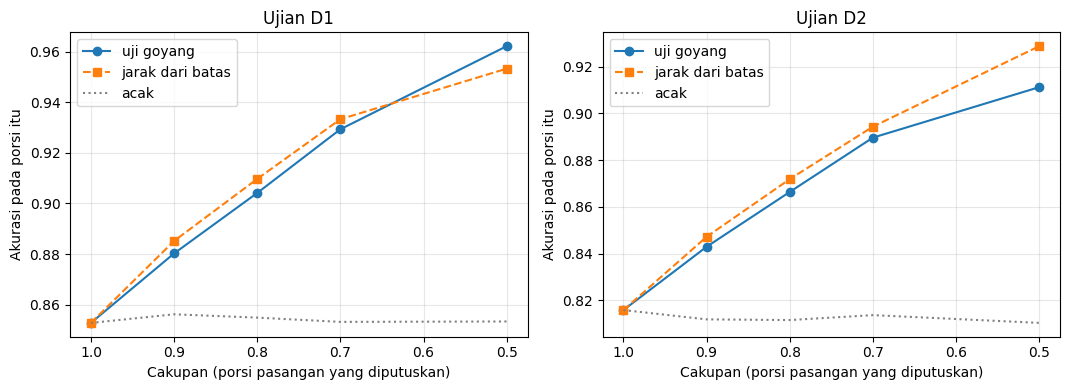

,dataset,cakupan,uji_goyang,jarak_dari_batas,acak
0,D1,1.0,0.8528,0.8528,0.8528
1,D1,0.9,0.8802,0.8852,0.8562
2,D1,0.8,0.9042,0.9097,0.8549
3,D1,0.7,0.9294,0.9333,0.8532
4,D1,0.5,0.9622,0.9533,0.8533
5,D2,1.0,0.8158,0.8158,0.8158
6,D2,0.9,0.8429,0.8471,0.8118
7,D2,0.8,0.8663,0.8718,0.8115
8,D2,0.7,0.8896,0.8943,0.8136
9,D2,0.5,0.9112,0.9287,0.8103


,akurasi_semua,akurasi_yakin,akurasi_ragu,porsi_ragu
D1,0.8528,0.9221,0.6673,0.2722
D2,0.8158,0.8569,0.6080,0.1650


Baca tabel: pada cakupan 0.8, 'uji_goyang' yang lebih tinggi dari 'jarak_dari_batas' berarti uji goyang lebih jitu memilih mana yang boleh diputuskan.


In [26]:
try:
    EMB_DIM = FINAL["base"].output_shape[-1]


    def jarak_goyang(base, images, pairs, n=N_SHAKE, seed=SEED, chunk=150):
        uniq_ = np.unique(np.concatenate([pairs.i1.values, pairs.i2.values]))
        pos_ = {int(u): k for k, u in enumerate(uniq_)}
        E = np.empty((len(uniq_), n, EMB_DIM), np.float32)
        for s in range(0, len(uniq_), chunk):
            part = uniq_[s:s + chunk]
            V = np.concatenate([shake_variants(images[u, :, :, 0].astype(np.float32), n, seed + int(u)) for u in part])
            E[s:s + len(part)] = base.predict(V, batch_size=128, verbose=0).reshape(len(part), n, -1)
        a = E[[pos_[int(i)] for i in pairs.i1.values]]
        b = E[[pos_[int(i)] for i in pairs.i2.values]]
        return np.linalg.norm(a - b, axis=2)            # (jumlah pasangan, n)


    def keyakinan(dm, thr):
        mean, std = dm.mean(1), dm.std(1)
        return np.abs(mean - thr) / (std + 1e-3)


    def akurasi_per_cakupan(conf, benar, cakupan=(1.0, 0.9, 0.8, 0.7, 0.5)):
        urut = np.argsort(-conf)
        out = {}
        for c in cakupan:
            n = max(1, int(round(c * len(conf))))
            out[c] = float(np.mean(benar[urut[:n]]))
        return out


    imgs_final = IMAGES[FINAL_MODE]
    dm_val = jarak_goyang(FINAL["base"], imgs_final, FINAL_VAL)
    z_val = keyakinan(dm_val, FINAL_THR)
    RAGU_Z = float(np.quantile(z_val, ABSTAIN_FRAC))
    d_clean_val = jarak(FINAL["emb"], FINAL_VAL)
    RAGU_MARGIN = float(np.quantile(np.abs(d_clean_val - FINAL_THR), ABSTAIN_FRAC))
    print(f"Batas 'ragu' dari validasi (bagian {ABSTAIN_FRAC:.0%} paling tidak yakin): z < {RAGU_Z:.2f}")

    GOYANG = {}
    rows = []
    fig, axes = plt.subplots(1, len(TESTS), figsize=(5.4 * len(TESTS), 4), squeeze=False)
    for ax, (tk, p) in zip(axes[0], TESTS.items()):
        dm = jarak_goyang(FINAL["base"], imgs_final, p)
        z = keyakinan(dm, FINAL_THR)
        d_clean = jarak(FINAL["emb"], p)
        benar = ((d_clean >= FINAL_THR).astype(int) == p.label.values).astype(float)
        margin = np.abs(d_clean - FINAL_THR)
        rg = np.random.default_rng(SEED)
        cov = (1.0, 0.9, 0.8, 0.7, 0.5)
        acc_g = akurasi_per_cakupan(z, benar, cov)
        acc_m = akurasi_per_cakupan(margin, benar, cov)
        acc_r = akurasi_per_cakupan(rg.random(len(z)), benar, cov)
        for c in cov:
            rows.append({"dataset": tk, "cakupan": c, "uji_goyang": acc_g[c], "jarak_dari_batas": acc_m[c], "acak": acc_r[c]})
        yakin = z >= RAGU_Z
        GOYANG[tk] = {
            "akurasi_semua": float(benar.mean()),
            "akurasi_yakin": float(benar[yakin].mean()) if yakin.any() else float("nan"),
            "akurasi_ragu": float(benar[~yakin].mean()) if (~yakin).any() else float("nan"),
            "porsi_ragu": float((~yakin).mean()),
        }
        ax.plot(cov, [acc_g[c] for c in cov], "o-", label="uji goyang")
        ax.plot(cov, [acc_m[c] for c in cov], "s--", label="jarak dari batas")
        ax.plot(cov, [acc_r[c] for c in cov], ":", color="gray", label="acak")
        ax.set_xlabel("Cakupan (porsi pasangan yang diputuskan)"); ax.set_ylabel("Akurasi pada porsi itu")
        ax.set_title(f"Ujian {tk}"); ax.grid(alpha=.3); ax.legend(); ax.invert_xaxis()
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "10_uji_goyang.png"), dpi=150); plt.show()

    TABEL_GOYANG = pd.DataFrame(rows)
    display(TABEL_GOYANG.round(4))
    display(pd.DataFrame(GOYANG).T.round(4))
    TABEL_GOYANG.round(4).to_csv(os.path.join(OUT_DIR, "tabel_uji_goyang.csv"), index=False)
    print("Baca tabel: pada cakupan 0.8, 'uji_goyang' yang lebih tinggi dari 'jarak_dari_batas' berarti uji goyang lebih jitu memilih mana yang boleh diputuskan.")
except Exception:
    traceback.print_exc()
    GAGAL.append('uji goyang')

## 17. Ciri forensik klasik + fusi dengan model

Ciri-ciri sederhana dihitung dengan OpenCV: bentuk, kepadatan tinta, kemiringan, ketebalan goresan, jumlah bagian terpisah, panjang goresan, dan letak pusat tinta. Dua kegunaan:
1. **Laporan forensik**: menjelaskan *kenapa* dua tanda tangan dianggap beda.
2. **Fusi**: ciri ini digabung dengan jarak model. Diuji apakah error turun (dilatih di data validasi, diuji di data ujian).

,dataset,skenario,auc,eer,accuracy,FAR,FRR
0,D1,model saja,0.9321,0.1533,0.8528,0.1078,0.1867
1,D1,ciri klasik saja,0.8688,0.2044,0.7944,0.3600,0.0511
2,D1,fusi (model + ciri),0.9346,0.1456,0.8561,0.1322,0.1556
3,D2,model saja,0.8999,0.1815,0.8158,0.1491,0.2193
4,D2,ciri klasik saja,0.7945,0.2823,0.7023,0.1064,0.4890
5,D2,fusi (model + ciri),0.8977,0.1859,0.8103,0.1338,0.2456


Pengaruh tiap ciri pada keputusan fusi (nilai besar = berpengaruh besar; positif = makin beda makin dicurigai palsu):


,bobot
jarak_model,2.477
kemiringan,0.350
ketebalan_goresan,-0.335
jumlah_bagian,0.301
posisi_x,-0.211
panjang_goresan,0.196
rasio_lebar_tinggi,-0.193
kepadatan_tinta,0.191
posisi_y,0.170


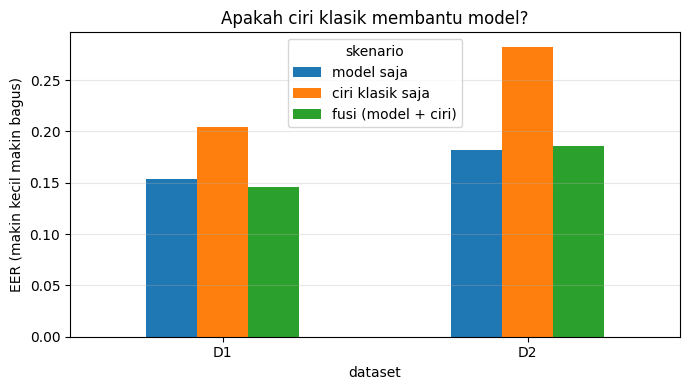


Contoh laporan forensik untuk satu pasangan TIRUAN dari data ujian:
  - Bentuk (lebar dibanding tinggi): pembanding 2.39, diperiksa 1.14 (agak beda).
  - Kepadatan tinta: pembanding 11.0%, diperiksa 6.6% (agak beda).
  - Kemiringan umum: pembanding -12 derajat, diperiksa -1 derajat (mirip).
  - Ketebalan goresan: pembanding 5.45, diperiksa 2.70 (beda).
  - Jumlah bagian terpisah (angkat pena): pembanding 2 bagian, diperiksa 1 bagian (mirip).
  - Panjang total goresan: pembanding 1.79, diperiksa 1.76 (mirip).
  - Letak pusat tinta (kiri-kanan): pembanding 49%, diperiksa 51% (mirip).
  - Letak pusat tinta (atas-bawah): pembanding 47%, diperiksa 33% (agak beda).


In [27]:
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler


    def pair_diffs(pairs):
        return np.stack([feature_diffs(FEATS[a], FEATS[b]) for a, b in zip(pairs.i1.values, pairs.i2.values)])


    def cocok(Xv, yv):
        sc = StandardScaler().fit(Xv)
        lr = LogisticRegression(max_iter=3000, C=1.0).fit(sc.transform(Xv), yv)
        return sc, lr


    def skor(sc, lr, X):
        return lr.decision_function(sc.transform(X))


    Xv_f = pair_diffs(FINAL_VAL)
    dv = jarak(FINAL["emb"], FINAL_VAL)
    yv = FINAL_VAL.label.values
    sc_f, lr_f = cocok(Xv_f, yv)                                   # hanya ciri klasik
    sc_u, lr_u = cocok(np.column_stack([dv, Xv_f]), yv)            # fusi: jarak model + ciri klasik

    SKENARIO = {}
    for nama in ("model saja", "ciri klasik saja", "fusi (model + ciri)"):
        if nama == "model saja":
            sv = dv
        elif nama == "ciri klasik saja":
            sv = skor(sc_f, lr_f, Xv_f)
        else:
            sv = skor(sc_u, lr_u, np.column_stack([dv, Xv_f]))
        _, thr_s = eer_and_threshold(yv, sv)
        SKENARIO[nama] = thr_s

    baris = []
    for tk, p in TESTS.items():
        Xt = pair_diffs(p); dt = jarak(FINAL["emb"], p); yt = p.label.values
        sk = {"model saja": dt, "ciri klasik saja": skor(sc_f, lr_f, Xt), "fusi (model + ciri)": skor(sc_u, lr_u, np.column_stack([dt, Xt]))}
        for nama, s in sk.items():
            mt = metrics_at(s, yt, SKENARIO[nama])
            baris.append({"dataset": tk, "skenario": nama, "auc": mt["auc"], "eer": mt["eer"],
                          "accuracy": mt["accuracy"], "FAR": mt["FAR"], "FRR": mt["FRR"]})
    TABEL_FUSI = pd.DataFrame(baris)
    display(TABEL_FUSI.round(4))
    TABEL_FUSI.round(4).to_csv(os.path.join(OUT_DIR, "tabel_fusi.csv"), index=False)

    koef = pd.Series(lr_u.coef_[0], index=["jarak_model"] + NAMA_CIRI).sort_values(key=np.abs, ascending=False)
    print("Pengaruh tiap ciri pada keputusan fusi (nilai besar = berpengaruh besar; positif = makin beda makin dicurigai palsu):")
    display(koef.round(3).to_frame("bobot"))

    fig, ax = plt.subplots(figsize=(7, 4))
    pv = TABEL_FUSI.pivot(index="dataset", columns="skenario", values="eer")[["model saja", "ciri klasik saja", "fusi (model + ciri)"]]
    pv.plot(kind="bar", ax=ax); ax.set_ylabel("EER (makin kecil makin bagus)"); ax.set_title("Apakah ciri klasik membantu model?")
    plt.xticks(rotation=0); ax.grid(axis="y", alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "11_fusi_ciri.png"), dpi=150); plt.show()

    # Batas "mirip / agak beda / beda" untuk laporan forensik: dari selisih pada pasangan ASLI di data latih
    trp = FINAL["train_pairs"] if RES_B is not None else PAIRS[("D1", "train")]
    dg = pair_diffs(trp[trp.label == 0])
    FORENSIK_BATAS = {n: [float(np.percentile(dg[:, i], 75)), float(np.percentile(dg[:, i], 95))] for i, n in enumerate(NAMA_CIRI)}

    print("\nContoh laporan forensik untuk satu pasangan TIRUAN dari data ujian:")
    pk = TESTS[list(TESTS)[0]]
    r = pk[pk.pair_type == "skilled_forgery"].iloc[0] if (pk.pair_type == "skilled_forgery").any() else pk[pk.label == 1].iloc[0]
    for baris_ in explain(FEATS[r.i1], FEATS[r.i2], FORENSIK_BATAS):
        print("  -", baris_["kalimat"])
except Exception:
    traceback.print_exc()
    GAGAL.append('fusi ciri')

## 18. Menyimpan model untuk aplikasi demo

Sebelum disimpan, model dimuat ulang dari file dan dicek hasilnya sama (supaya tidak ada kejutan di aplikasi demo).

In [28]:
import zipfile

model_path = os.path.join(OUT_DIR, "embedding_model.keras")
FINAL["base"].save(model_path)

# cek: muat ulang dari file, hasilnya harus sama
cek = IMAGES[FINAL_MODE][:6].astype(np.float32)
dimuat = tf.keras.models.load_model(model_path, compile=False)
assert np.allclose(FINAL["base"].predict(cek, verbose=0), dimuat.predict(cek, verbose=0), atol=1e-4), "Model hasil muat ulang berbeda!"
print("Cek simpan/muat model: OK")


def bersih(o):
    if isinstance(o, dict):
        return {str(k): bersih(v) for k, v in o.items() if k != "confusion_matrix"}
    if isinstance(o, (list, tuple)):
        return [bersih(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o


m_utama = FINAL["metrics"]
config = {
    "model": FINAL_NAME,
    "img_h": IMG_H, "img_w": IMG_W,
    "preprocess_mode": FINAL_MODE,
    "threshold": float(FINAL_THR),
    "margin": MARGIN,
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "metrics": {
        **{f"test_{k}": v for k, v in m_utama[list(m_utama)[0]].items() if k != "confusion_matrix"},
        "per_dataset": m_utama,
    },
    "fusi": None if sc_u is None else {
        "fitur": ["jarak_model"] + NAMA_CIRI,
        "mean": sc_u.mean_.tolist(), "scale": sc_u.scale_.tolist(),
        "coef": lr_u.coef_[0].tolist(), "intercept": float(lr_u.intercept_[0]),
        "threshold": float(SKENARIO["fusi (model + ciri)"]),
        "hasil": TABEL_FUSI.round(4).to_dict(orient="records"),
    },
    "forensik_batas": FORENSIK_BATAS,
    "goyang": {"n": N_SHAKE, "ragu_z": RAGU_Z, "ragu_margin": RAGU_MARGIN, "abstain_frac": ABSTAIN_FRAC, "hasil": GOYANG},
    "banyak_pembanding": MULTI,
}
with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
    json.dump(bersih(config), f, indent=2)

for nama in ("preprocess.py", "forensik.py", "gangguan.py"):
    shutil.copy(nama, os.path.join(OUT_DIR, nama))

zip_demo = os.path.join(OUT_DIR, "demo_model_files.zip")
with zipfile.ZipFile(zip_demo, "w", zipfile.ZIP_DEFLATED) as z:
    for nama in ("embedding_model.keras", "config.json", "preprocess.py", "forensik.py", "gangguan.py"):
        z.write(os.path.join(OUT_DIR, nama), nama)

zip_lap = os.path.join(OUT_DIR, "hasil_laporan.zip")
with zipfile.ZipFile(zip_lap, "w", zipfile.ZIP_DEFLATED) as z:
    for akar, _, fs in os.walk(OUT_DIR):
        for f in fs:
            if f.endswith((".png", ".csv", ".json")):
                z.write(os.path.join(akar, f), os.path.relpath(os.path.join(akar, f), OUT_DIR))

print("Tersimpan di:", OUT_DIR)
print("demo_model_files.zip :", zipfile.ZipFile(zip_demo).namelist())
print("hasil_laporan.zip    :", len(zipfile.ZipFile(zip_lap).namelist()), "file (grafik dan tabel)")
if os.path.exists("/kaggle/working"):
    for _z in (zip_demo, zip_lap):
        shutil.copy(_z, "/kaggle/working/" + os.path.basename(_z))
    print("Kaggle: salinan zip ada di /kaggle/working (tab Output).")
try:
    from google.colab import files
    files.download(zip_demo)
    files.download(zip_lap)
except Exception as e:
    print("Unduh manual dari panel file di kiri:", e)

Cek simpan/muat model: OK
Tersimpan di: /kaggle/working/ttd_siamese_output
demo_model_files.zip : ['embedding_model.keras', 'config.json', 'preprocess.py', 'forensik.py', 'gangguan.py']
hasil_laporan.zip    : 19 file (grafik dan tabel)
Kaggle: salinan zip ada di /kaggle/working (tab Output).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Ringkasan untuk laporan

In [29]:
def baris_ringkas(tk):
    m = FINAL["metrics"][tk]
    return (f"  [{tk}] AUC {m['auc']:.4f} | EER {m['eer']:.4f} | Akurasi {m['accuracy']:.4f} | "
            f"FAR {m['FAR']:.4f} (palsu lolos) | FRR {m['FRR']:.4f} (asli ditolak)")

print(f"""
RINGKASAN
=========
Model akhir               : {FINAL_NAME}
Pengolahan citra terbaik  : {BEST_MODE} (dipilih dari validasi)
Batas jarak (dari validasi): {FINAL_THR:.4f}
Data: {meta.writer.nunique()} orang, {len(meta)} gambar ({', '.join(f'{t}: {n}' for t, n in meta.groupby('dataset').writer.nunique().items())} orang)

Hasil pada orang yang belum pernah dilihat saat training:""")
for tk in TESTS:
    print(baris_ringkas(tk))
print("\nCatatan: D1 = dataset 1 (sumber sama dengan data latih), D2 = dataset 2." +
      (" Pada percobaan A, D2 adalah ujian lintas dataset sungguhan (model belum pernah melihatnya)." if HAS_D2 else ""))
if HAS_D2:
    print("\nPercobaan A (latih D1 saja) di D2 ujian, per cara pengolahan citra:")
    for m, r in RES_A.items():
        v = r["metrics"]["D2"]
        print(f"  {m:7s} AUC {v['auc']:.4f} | EER {v['eer']:.4f}")
print("\nSemua grafik dan tabel ada di:", OUT_DIR)
if GAGAL:
    print("\nBAGIAN YANG GAGAL (salin pesan errornya ke Claude):", GAGAL)


RINGKASAN
Model akhir               : gabungan D1+D2
Pengolahan citra terbaik  : binary (dipilih dari validasi)
Batas jarak (dari validasi): 0.4811
Data: 175 orang, 3914 gambar (D1: 55, D2: 120 orang)

Hasil pada orang yang belum pernah dilihat saat training:
  [D1] AUC 0.9321 | EER 0.1533 | Akurasi 0.8528 | FAR 0.1078 (palsu lolos) | FRR 0.1867 (asli ditolak)
  [D2] AUC 0.8999 | EER 0.1815 | Akurasi 0.8158 | FAR 0.1491 (palsu lolos) | FRR 0.2193 (asli ditolak)

Catatan: D1 = dataset 1 (sumber sama dengan data latih), D2 = dataset 2. Pada percobaan A, D2 adalah ujian lintas dataset sungguhan (model belum pernah melihatnya).

Percobaan A (latih D1 saja) di D2 ujian, per cara pengolahan citra:
  raw     AUC 0.7471 | EER 0.3246
  binary  AUC 0.7720 | EER 0.3092

Semua grafik dan tabel ada di: /kaggle/working/ttd_siamese_output
